# Исследование рынка заведений общественного питания Москвы

- Автор: Никитин Я.В.
- Дата: 14.09.2026

### Цели и задачи проекта

**Цель проекта**

Исследовать рынок заведений общественного питания Москвы и на основе анализа данных определить особенности рынка, которые помогут инвесторам выбрать подходящий формат заведения, его расположение и ценовой сегмент.

**Задачи проекта**

* изучить и подготовить данные о заведениях общественного питания Москвы;
* проанализировать представленные категории заведений и их распределение по административным округам;
* исследовать соотношение сетевых и несетевых заведений;
* изучить количество посадочных мест и выявить возможные выбросы;
* проанализировать рейтинги заведений и различия между категориями;
* исследовать взаимосвязи между характеристиками заведений с помощью коэффициента `phi_k`;
* определить наиболее популярные сети Москвы;
* сравнить средний чек в разных административных округах и отдельно изучить ЦАО;
* сформулировать основные выводы и рекомендации для инвесторов.


### Описание данных

Для исследования используются два набора данных о заведениях общественного питания Москвы. Данные собраны на основе информации из Яндекс Карт и Яндекс Бизнес за лето 2022 года.

**`/datasets/rest_info.csv`**

Файл содержит общую информацию о заведениях:

* `name` — название заведения;
* `address` — адрес;
* `district` — административный округ Москвы;
* `category` — категория заведения: кафе, пиццерия, кофейня и др.;
* `hours` — дни и часы работы;
* `rating` — пользовательский рейтинг в Яндекс Картах, максимальное значение — 5.0;
* `chain` — принадлежность к сети: `0` — несетевое заведение, `1` — сетевое;
* `seats` — количество посадочных мест.

**`/datasets/rest_price.csv`**

Файл содержит информацию о ценах:

* `price` — ценовая категория заведения;
* `avg_bill` — текстовая информация о стоимости, например средний счёт, цена чашки капучино или бокала пива;
* `middle_avg_bill` — числовая оценка среднего чека. Заполняется только для заведений, где указана информация о среднем счёте;
* `middle_coffee_cup` — числовая оценка стоимости одной чашки капучино. Заполняется только для заведений, где указана соответствующая информация.

### Особенности данных

Информация из Яндекс Бизнес может быть добавлена пользователями или получена из открытых источников, поэтому она носит справочный характер. Для небольших сетей возможны ошибки в определении принадлежности заведения к сети.


### Содержимое проекта

1. **Загрузка данных и знакомство с ними**

   * Загрузка данных
   * Изучение общей информации
   * Промежуточный вывод
   * Подготовка единого датафрейма

2. **Предобработка данных**

   * Проверка и преобразование типов данных
   * Анализ и обработка пропущенных значений
   * Поиск и обработка явных и неявных дубликатов
   * Нормализация текстовых данных
   * Создание признака `is_24_7`
   * Промежуточный вывод

3. **Исследовательский анализ данных**

   * Анализ категорий заведений
   * Анализ распределения заведений по административным округам и категорий в ЦАО
   * Анализ сетевых и несетевых заведений
   * Анализ количества посадочных мест
   * Анализ рейтингов заведений
   * Исследование взаимосвязей рейтинга с другими признаками
   * Анализ популярных сетей
   * Анализ среднего чека по административным округам
   * Промежуточный вывод

4. **Итоговый вывод и рекомендации**

   * Общий обзор проведённого исследования
   * Основные результаты и ответы на исследовательские вопросы
   * Рекомендации для заказчика


## 1. Загрузка данных и знакомство с ними

- Загружаем данные о заведениях общественного питания Москвы.

In [1]:
# !pip install phik -U -q

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import phik

In [3]:
try:
    rest_info = pd.read_csv('/datasets/rest_info.csv')
    rest_price = pd.read_csv('/datasets/rest_price.csv')
except FileNotFoundError:
    rest_info = pd.read_csv('rest_info.csv')
    rest_price = pd.read_csv('rest_price.csv')

- Познакомьтесь с данными и изучите общую информацию о них.

In [4]:
rest_info.head()

,id,name,category,address,district,hours,rating,chain,seats
0,0c3e3439a8c64ea5bf6ecd6ca6ae19f0,WoWфли,кафе,"Москва, улица Дыбенко, 7/1",Северный административный округ,"ежедневно, 10:00–22:00",5.0,0,NaN
1,045780ada3474c57a2112e505d74b633,Четыре комнаты,ресторан,"Москва, улица Дыбенко, 36, корп. 1",Северный административный округ,"ежедневно, 10:00–22:00",4.5,0,4.0
2,1070b6b59144425896c65889347fcff6,Хазри,кафе,"Москва, Клязьминская улица, 15",Северный административный округ,"пн-чт 11:00–02:00; пт,сб 11:00–05:00; вс 11:00...",4.6,0,45.0
3,03ac7cd772104f65b58b349dc59f03ee,Dormouse Coffee Shop,кофейня,"Москва, улица Маршала Федоренко, 12",Северный административный округ,"ежедневно, 09:00–22:00",5.0,0,NaN
4,a163aada139c4c7f87b0b1c0b466a50f,Иль Марко,пиццерия,"Москва, Правобережная улица, 1Б",Северный административный округ,"ежедневно, 10:00–22:00",5.0,1,148.0


In [5]:
rest_info.info()

<class 'pandas.DataFrame'>
RangeIndex: 8406 entries, 0 to 8405
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        8406 non-null   str    
 1   name      8406 non-null   str    
 2   category  8406 non-null   str    
 3   address   8406 non-null   str    
 4   district  8406 non-null   str    
 5   hours     7870 non-null   str    
 6   rating    8406 non-null   float64
 7   chain     8406 non-null   int64  
 8   seats     4795 non-null   float64
dtypes: float64(2), int64(1), str(6)
memory usage: 2.4 MB


In [6]:
rest_info.shape

(8406, 9)

In [7]:
rest_price.head()

,id,price,avg_bill,middle_avg_bill,middle_coffee_cup
0,045780ada3474c57a2112e505d74b633,выше среднего,Средний счёт:1500–1600 ₽,1550.0,NaN
1,1070b6b59144425896c65889347fcff6,средние,Средний счёт:от 1000 ₽,1000.0,NaN
2,03ac7cd772104f65b58b349dc59f03ee,NaN,Цена чашки капучино:155–185 ₽,NaN,170.0
3,a163aada139c4c7f87b0b1c0b466a50f,средние,Средний счёт:400–600 ₽,500.0,NaN
4,8a343546b24e4a499ad96eb7d0797a8a,средние,NaN,NaN,NaN


In [8]:
rest_price.info()

<class 'pandas.DataFrame'>
RangeIndex: 4058 entries, 0 to 4057
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 4058 non-null   str    
 1   price              3315 non-null   str    
 2   avg_bill           3816 non-null   str    
 3   middle_avg_bill    3149 non-null   float64
 4   middle_coffee_cup  535 non-null    float64
dtypes: float64(2), str(3)
memory usage: 481.7 KB


In [9]:
rest_price.shape

(4058, 5)

---

### Промежуточный вывод

В исследовании представлены два датасета:

* `rest_info` - 8 406 строк и 9 столбцов;
* `rest_price` - 4 058 строк и 5 столбцов.

Датасет `rest_info` содержит информацию о заведениях: название, категорию, адрес, административный округ, часы работы, рейтинг, принадлежность к сети и количество посадочных мест. В датасете есть пропуски в столбцах `hours` и `seats`. Особенно много пропусков наблюдается в `seats` - заполнено 4 795 из 8 406 значений.

Датасет `rest_price` содержит информацию о ценовой категории и стоимости. В нём есть пропуски в `price`, `avg_bill`, `middle_avg_bill` и `middle_coffee_cup`. Количество пропусков в ценовых признаках различается, что связано в том числе с особенностями представления информации о ценах: например, `middle_coffee_cup` заполняется только для заведений, где указана стоимость чашки капучино.

Типы данных соответствуют содержимому столбцов: текстовые признаки имеют строковый тип, количественные признаки - числовой. На этапе предобработки необходимо дополнительно изучить причины пропусков, проверить корректность типов данных и наличие дубликатов.

Далее два датасета необходимо объединить по идентификатору заведения `id` и подготовить единый датафрейм для дальнейшего анализа.


### Подготовка единого датафрейма

- Объединяем данные двух датасетов в один, с которым и продолжим работу.

In [10]:
# Пример с дубликатами
df_left = pd.DataFrame({'id': [1, 1, 1, 2], 'value': ['A', 'B', 'C', 'D']})
df_right = pd.DataFrame({'id': [1, 1, 3], 'price': [100, 200, 300]})
display(df_left, df_right)

,id,value
0,1,A
1,1,B
2,1,C
3,2,D


,id,price
0,1,100
1,1,200
2,3,300


In [11]:
# Пример с дубликатами
pd.merge(df_left, df_right, on='id', how='left')

,id,value,price
0,1,A,100.0
1,1,A,200.0
2,1,B,100.0
3,1,B,200.0
4,1,C,100.0
5,1,C,200.0
6,2,D,NaN


In [12]:
# Пример с дубликатами
pd.merge(df_left, df_right, on='id', how='inner')

,id,value,price
0,1,A,100
1,1,A,200
2,1,B,100
3,1,B,200
4,1,C,100
5,1,C,200


In [13]:
# Пример с дубликатами
pd.merge(df_left, df_right, on='id', how='outer')

,id,value,price
0,1,A,100.0
1,1,A,200.0
2,1,B,100.0
3,1,B,200.0
4,1,C,100.0
5,1,C,200.0
6,2,D,NaN
7,3,NaN,300.0


Перед объединением проверим, есть ли дубликаты в столбце `id` в обоих датасетах. Это необходимо, чтобы избежать некорректного увеличения количества строк при объединении.

In [14]:
print('Количество дубликатов id в rest_info:', rest_info['id'].duplicated().sum())
print('Количество дубликатов id в rest_price:', rest_price['id'].duplicated().sum())

Количество дубликатов id в rest_info: 0
Количество дубликатов id в rest_price: 0


Теперь объединяем данные двух датасетов в один, с которым и продолжим работу.

In [15]:
df = rest_info.merge(rest_price, on='id', how='left')

print('Размер датафрейма:', df.shape)

print('\nОбщая информация о датафрейме:')
df.info()

print('\nПервые пять строк датафрейма:')
print(df.head())

Размер датафрейма: (8406, 13)

Общая информация о датафрейме:
<class 'pandas.DataFrame'>
RangeIndex: 8406 entries, 0 to 8405
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 8406 non-null   str    
 1   name               8406 non-null   str    
 2   category           8406 non-null   str    
 3   address            8406 non-null   str    
 4   district           8406 non-null   str    
 5   hours              7870 non-null   str    
 6   rating             8406 non-null   float64
 7   chain              8406 non-null   int64  
 8   seats              4795 non-null   float64
 9   price              3315 non-null   str    
 10  avg_bill           3816 non-null   str    
 11  middle_avg_bill    3149 non-null   float64
 12  middle_coffee_cup  535 non-null    float64
dtypes: float64(4), int64(1), str(8)
memory usage: 2.8 MB

Первые пять строк датафрейма:
                                 

После объединения получили единый датафрейм размером 8 406 строк и 13 столбцов. Все записи из основного датасета `rest_info` сохранились, а информация о ценах из `rest_price` была добавлена по идентификатору заведения `id`.

Проверка первых строк, структуры и типов данных показала, что объединение выполнено корректно.

Дополнительно изучим числовые признаки и количество уникальных значений в столбцах объединённого датафрейма.

In [16]:
print('Основные статистические характеристики:')
print(df.describe())

print('\nКоличество уникальных значений в столбцах:')
print(df.nunique())

Основные статистические характеристики:
            rating        chain        seats  middle_avg_bill  \
count  8406.000000  8406.000000  4795.000000      3149.000000   
mean      4.229895     0.381275   108.421689       958.053668   
std       0.470348     0.485729   122.833396      1009.732845   
min       1.000000     0.000000     0.000000         0.000000   
25%       4.100000     0.000000    40.000000       375.000000   
50%       4.300000     0.000000    75.000000       750.000000   
75%       4.400000     1.000000   140.000000      1250.000000   
max       5.000000     1.000000  1288.000000     35000.000000   

       middle_coffee_cup  
count         535.000000  
mean          174.721495  
std            88.951103  
min            60.000000  
25%           124.500000  
50%           169.000000  
75%           225.000000  
max          1568.000000  

Количество уникальных значений в столбцах:
id                   8406
name                 5614
category                8
address  

**После объединения получили единый датафрейм со всеми заведениями из `rest_info` и дополнительными ценовыми признаками из `rest_price`. Проверка статистических характеристик и количества уникальных значений помогает убедиться в структуре данных и подготовить их к дальнейшей предобработке.**

## 2. Предобработка данных

Подготавливаем данные к исследовательскому анализу:

- Изучаем корректность типов данных и при необходимости проводим их преобразование.

In [17]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8406 entries, 0 to 8405
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 8406 non-null   str    
 1   name               8406 non-null   str    
 2   category           8406 non-null   str    
 3   address            8406 non-null   str    
 4   district           8406 non-null   str    
 5   hours              7870 non-null   str    
 6   rating             8406 non-null   float64
 7   chain              8406 non-null   int64  
 8   seats              4795 non-null   float64
 9   price              3315 non-null   str    
 10  avg_bill           3816 non-null   str    
 11  middle_avg_bill    3149 non-null   float64
 12  middle_coffee_cup  535 non-null    float64
dtypes: float64(4), int64(1), str(8)
memory usage: 2.8 MB


**Типы данных в датафрейме соответствуют содержимому столбцов. Текстовые признаки имеют строковый тип, количественные признаки - числовой, признак `chain` представлен целыми числами. Преобразование типов данных не требуется.**

Проверим наиболее часто встречающиеся значения в столбцах, чтобы убедиться, что фактическое содержимое соответствует указанным типам данных. Особое внимание уделим числовым и категориальным признакам.

In [18]:
for column in df.columns:
    print(f'\nСтолбец: {column}')
    print('Тип данных:', df[column].dtype)
    print('Наиболее частые значения:')
    print(df[column].value_counts(dropna=False).head(10))


Столбец: id
Тип данных: str
Наиболее частые значения:
id
0c3e3439a8c64ea5bf6ecd6ca6ae19f0    1
045780ada3474c57a2112e505d74b633    1
1070b6b59144425896c65889347fcff6    1
03ac7cd772104f65b58b349dc59f03ee    1
a163aada139c4c7f87b0b1c0b466a50f    1
8a343546b24e4a499ad96eb7d0797a8a    1
96ebceb1a09e4e3191133b9fe0379a64    1
0243288b78024af090b8e947842c969c    1
36aeb0ffa69c48fdb0021549520deb10    1
487167877eb04288bc90d4fa80646fc2    1
Name: count, dtype: int64

Столбец: name
Тип данных: str
Наиболее частые значения:
name
Кафе                189
Шоколадница         120
Домино'с Пицца       76
Додо Пицца           74
One Price Coffee     71
Яндекс Лавка         69
Cofix                65
Prime                50
Хинкальная           44
Шаурма               43
Name: count, dtype: int64

Столбец: category
Тип данных: str
Наиболее частые значения:
category
кафе               2378
ресторан           2043
кофейня            1413
бар,паб             765
пиццерия            633
быстрое питание   

**Проверка наиболее частотных значений показала, что фактическое содержимое столбцов соответствует их типам данных. Числовые признаки содержат числовые значения, а текстовые признаки - названия, категории, адреса и текстовые описания. Признаков, требующих преобразования типов, не обнаружено.**

**Текущие типы данных подходят для дальнейшего анализа. Понижение разрядности числовых типов или перевод отдельных признаков в тип `category` не требуется.**


Изучаем пропущенные значения в данных: считаем их количество в каждом столбце датафрейма, изучаем данные с пропущенными значениями и предполагаем гипотезы их появления. Проводим обработку пропущенных значений: заменяем пропуски на определённое значение, удаляем строки с пропусками или оставляем их без изменений.

In [19]:
df.isna().sum()

id                      0
name                    0
category                0
address                 0
district                0
hours                 536
rating                  0
chain                   0
seats                3611
price                5091
avg_bill             4590
middle_avg_bill      5257
middle_coffee_cup    7871
dtype: int64

In [20]:
df[df['hours'].isna()].head(10)

,id,name,category,address,district,hours,rating,chain,seats,price,avg_bill,middle_avg_bill,middle_coffee_cup
38,3746fe879e5b43629512095693ce4113,Ижора,булочная,"Москва, Ижорский проезд, 5А",Северный административный округ,NaN,4.4,0,NaN,NaN,NaN,NaN,NaN
40,e5f4ff8c7196472eac2c980fc6b2e9b2,Кафе,кафе,"Москва, Ижорская улица, 18, стр. 1",Северный административный округ,NaN,3.7,0,NaN,NaN,NaN,NaN,NaN
44,0cb57ea286804a0fbff91ae2cc868d48,Кафетерий,кафе,"Москва, Ангарская улица, 24А",Северный административный округ,NaN,3.8,1,8.0,NaN,NaN,NaN,NaN
56,2b2b60640efb494b8ed4aa3b1313f1cd,Рыба из тандыра,быстрое питание,"Москва, Коровинское шоссе, 46, стр. 5",Северный административный округ,NaN,1.5,0,NaN,NaN,NaN,NaN,NaN
108,a9ad4bd7e15c4b8cb6295c745e5a11c1,Кафе,"бар,паб","Москва, МКАД, 82-й километр, вл18",Северо-Восточный административный округ,NaN,4.2,0,NaN,NaN,NaN,NaN,NaN
123,e14d752227704822964731977a47d198,Кафе,кафе,"Москва, Шенкурский проезд, 14",Северо-Восточный административный округ,NaN,4.3,0,50.0,NaN,NaN,NaN,NaN
126,77da9e57030c4ebf8c64968a4be78f71,Кулинария,кафе,"Москва, Череповецкая улица, 17",Северо-Восточный административный округ,NaN,3.9,1,NaN,NaN,NaN,NaN,NaN
138,fdfd314974d74b94980756c5ac2ce4a3,Хинкальная,быстрое питание,"Москва, Шенкурский проезд, 14",Северо-Восточный административный округ,NaN,4.1,1,50.0,NaN,NaN,NaN,NaN
217,f38e42e7d24e44b19ab3efd359c0e9f2,16 Июня,кафе,"Москва, бульвар Академика Ландау, 3",Северо-Восточный административный округ,NaN,1.4,0,NaN,NaN,NaN,NaN,NaN
274,cc4840626fc84b2daac8496282dc7e2c,Чайхана,кафе,"Москва, Широкая улица, 12",Северо-Восточный административный округ,NaN,3.0,1,50.0,NaN,NaN,NaN,NaN


**Пропуски в `hours` встречаются у заведений разных категорий. Так как `hours` является категориальным признаком, заменим пропуски на значение `Нет информации`. Это позволит сохранить такие записи в дальнейшем анализе.**


In [21]:
df[df['seats'].isna()].head(10)

,id,name,category,address,district,hours,rating,chain,seats,price,avg_bill,middle_avg_bill,middle_coffee_cup
0,0c3e3439a8c64ea5bf6ecd6ca6ae19f0,WoWфли,кафе,"Москва, улица Дыбенко, 7/1",Северный административный округ,"ежедневно, 10:00–22:00",5.0,0,NaN,NaN,NaN,NaN,NaN
3,03ac7cd772104f65b58b349dc59f03ee,Dormouse Coffee Shop,кофейня,"Москва, улица Маршала Федоренко, 12",Северный административный округ,"ежедневно, 09:00–22:00",5.0,0,NaN,NaN,Цена чашки капучино:155–185 ₽,NaN,170.0
5,8a343546b24e4a499ad96eb7d0797a8a,Sergio Pizza,пиццерия,"Москва, Ижорская улица, вл8Б",Северный административный округ,"ежедневно, 10:00–23:00",4.6,0,NaN,средние,NaN,NaN,NaN
11,53ac103717c142f29907080db1f0ce58,Шашлык Шефф,кафе,"Москва, улица Маршала Федоренко, 10с1",Северный административный округ,"ежедневно, 10:00–21:00",4.9,0,NaN,NaN,NaN,NaN,NaN
12,9384a51a4b2749759234df689b3a4857,Заправка,кафе,"Москва, МКАД, 80-й километр, 1",Северный административный округ,вт-сб 09:00–18:00,4.3,0,NaN,средние,Средний счёт:330 ₽,330.0,NaN
14,b9469750090f4a19829cc717bc369988,У Сильвы,"бар,паб","Москва, Ангарская улица, 42с1",Северный административный округ,"ежедневно, 13:00–00:00",4.2,0,NaN,выше среднего,Средний счёт:1500 ₽,1500.0,NaN
16,ccda3acc54e34bfcac4d6a25a5205bcb,База Стритфуд,кафе,"Москва, Базовская улица, 15, корп. 8",Северный административный округ,"ежедневно, 10:00–23:00",4.2,0,NaN,средние,Средний счёт:140–350 ₽,245.0,NaN
19,feec6bedccae44cb877d99c13f9aa5d7,Пекарня,булочная,"Москва, Ижорский проезд, 5",Северный административный округ,"ежедневно, круглосуточно",4.4,1,NaN,NaN,NaN,NaN,NaN
21,3483fb839c134fc89e15a1da83053498,7/12,кафе,"Москва, Прибрежный проезд, 7",Северный административный округ,"ежедневно, 10:00–22:00",4.5,0,NaN,NaN,NaN,NaN,NaN
22,66274ec5b26440e389aa3584b5cc2e9c,Крымские чебуреки,кафе,"Москва, Коровинское шоссе, 35, стр. 17",Северный административный округ,пн-пт 09:00–21:00,4.2,0,NaN,NaN,NaN,NaN,NaN


**Пропуски в `seats` встречаются у заведений разных категорий. При этом остальные данные о заведениях могут быть заполнены. Вероятнее всего, количество посадочных мест не было указано в источнике данных. Заполнять пропуски искусственными значениями нецелесообразно, поэтому оставляем их без изменений.**

In [22]:
df[df['price'].isna()].head(10)

,id,name,category,address,district,hours,rating,chain,seats,price,avg_bill,middle_avg_bill,middle_coffee_cup
0,0c3e3439a8c64ea5bf6ecd6ca6ae19f0,WoWфли,кафе,"Москва, улица Дыбенко, 7/1",Северный административный округ,"ежедневно, 10:00–22:00",5.0,0,NaN,NaN,NaN,NaN,NaN
3,03ac7cd772104f65b58b349dc59f03ee,Dormouse Coffee Shop,кофейня,"Москва, улица Маршала Федоренко, 12",Северный административный округ,"ежедневно, 09:00–22:00",5.0,0,NaN,NaN,Цена чашки капучино:155–185 ₽,NaN,170.0
11,53ac103717c142f29907080db1f0ce58,Шашлык Шефф,кафе,"Москва, улица Маршала Федоренко, 10с1",Северный административный округ,"ежедневно, 10:00–21:00",4.9,0,NaN,NaN,NaN,NaN,NaN
13,aea18265b0a0415893f1e796b82568fe,Буханка,булочная,"Москва, Базовская улица, 15, корп. 1",Северный административный округ,"ежедневно, 08:00–22:00",4.8,1,180.0,NaN,NaN,NaN,NaN
19,feec6bedccae44cb877d99c13f9aa5d7,Пекарня,булочная,"Москва, Ижорский проезд, 5",Северный административный округ,"ежедневно, круглосуточно",4.4,1,NaN,NaN,NaN,NaN,NaN
20,1ab5691e4da844d3abadf085e0957852,Чебуреки Манты,кафе,"Москва, Правобережная улица, 1Б",Северный административный округ,"ежедневно, 10:00–22:00",4.3,1,148.0,NaN,NaN,NaN,NaN
21,3483fb839c134fc89e15a1da83053498,7/12,кафе,"Москва, Прибрежный проезд, 7",Северный административный округ,"ежедневно, 10:00–22:00",4.5,0,NaN,NaN,NaN,NaN,NaN
22,66274ec5b26440e389aa3584b5cc2e9c,Крымские чебуреки,кафе,"Москва, Коровинское шоссе, 35, стр. 17",Северный административный округ,пн-пт 09:00–21:00,4.2,0,NaN,NaN,NaN,NaN,NaN
23,78709462f2b3480f825489a5321a3563,Буханка,булочная,"Москва, Лобненская улица, 13к2",Северный административный округ,"ежедневно, 08:00–22:00",4.7,1,NaN,NaN,NaN,NaN,NaN
24,0f5d22f5377340d0a81a9328e6ebdcac,Drive Café,кафе,"Москва, улица Дыбенко, 9Ас1",Северный административный округ,"ежедневно, круглосуточно",4.0,1,NaN,NaN,NaN,NaN,NaN


**Пропуски в `price` встречаются у заведений разных категорий. Так как `price` является категориальным признаком, заменим пропуски на значение `Нет информации`. Это позволит сохранить такие записи в дальнейшем анализе.**


In [23]:
df[df['avg_bill'].isna()].head(10)

,id,name,category,address,district,hours,rating,chain,seats,price,avg_bill,middle_avg_bill,middle_coffee_cup
0,0c3e3439a8c64ea5bf6ecd6ca6ae19f0,WoWфли,кафе,"Москва, улица Дыбенко, 7/1",Северный административный округ,"ежедневно, 10:00–22:00",5.0,0,NaN,NaN,NaN,NaN,NaN
5,8a343546b24e4a499ad96eb7d0797a8a,Sergio Pizza,пиццерия,"Москва, Ижорская улица, вл8Б",Северный административный округ,"ежедневно, 10:00–23:00",4.6,0,NaN,средние,NaN,NaN,NaN
11,53ac103717c142f29907080db1f0ce58,Шашлык Шефф,кафе,"Москва, улица Маршала Федоренко, 10с1",Северный административный округ,"ежедневно, 10:00–21:00",4.9,0,NaN,NaN,NaN,NaN,NaN
13,aea18265b0a0415893f1e796b82568fe,Буханка,булочная,"Москва, Базовская улица, 15, корп. 1",Северный административный округ,"ежедневно, 08:00–22:00",4.8,1,180.0,NaN,NaN,NaN,NaN
19,feec6bedccae44cb877d99c13f9aa5d7,Пекарня,булочная,"Москва, Ижорский проезд, 5",Северный административный округ,"ежедневно, круглосуточно",4.4,1,NaN,NaN,NaN,NaN,NaN
20,1ab5691e4da844d3abadf085e0957852,Чебуреки Манты,кафе,"Москва, Правобережная улица, 1Б",Северный административный округ,"ежедневно, 10:00–22:00",4.3,1,148.0,NaN,NaN,NaN,NaN
21,3483fb839c134fc89e15a1da83053498,7/12,кафе,"Москва, Прибрежный проезд, 7",Северный административный округ,"ежедневно, 10:00–22:00",4.5,0,NaN,NaN,NaN,NaN,NaN
22,66274ec5b26440e389aa3584b5cc2e9c,Крымские чебуреки,кафе,"Москва, Коровинское шоссе, 35, стр. 17",Северный административный округ,пн-пт 09:00–21:00,4.2,0,NaN,NaN,NaN,NaN,NaN
23,78709462f2b3480f825489a5321a3563,Буханка,булочная,"Москва, Лобненская улица, 13к2",Северный административный округ,"ежедневно, 08:00–22:00",4.7,1,NaN,NaN,NaN,NaN,NaN
24,0f5d22f5377340d0a81a9328e6ebdcac,Drive Café,кафе,"Москва, улица Дыбенко, 9Ас1",Северный административный округ,"ежедневно, круглосуточно",4.0,1,NaN,NaN,NaN,NaN,NaN


**Пропуски в `avg_bill` встречаются у заведений разных категорий. Так как `avg_bill` является категориальным признаком, заменим пропуски на значение `Нет информации`. Это позволит не исключать такие записи из анализа.**


In [24]:
df[df['middle_avg_bill'].isna()].head(10)

,id,name,category,address,district,hours,rating,chain,seats,price,avg_bill,middle_avg_bill,middle_coffee_cup
0,0c3e3439a8c64ea5bf6ecd6ca6ae19f0,WoWфли,кафе,"Москва, улица Дыбенко, 7/1",Северный административный округ,"ежедневно, 10:00–22:00",5.0,0,NaN,NaN,NaN,NaN,NaN
3,03ac7cd772104f65b58b349dc59f03ee,Dormouse Coffee Shop,кофейня,"Москва, улица Маршала Федоренко, 12",Северный административный округ,"ежедневно, 09:00–22:00",5.0,0,NaN,NaN,Цена чашки капучино:155–185 ₽,NaN,170.0
5,8a343546b24e4a499ad96eb7d0797a8a,Sergio Pizza,пиццерия,"Москва, Ижорская улица, вл8Б",Северный административный округ,"ежедневно, 10:00–23:00",4.6,0,NaN,средние,NaN,NaN,NaN
10,ac32978af97641bfacf996e7f5a50ee5,Great Room Bar,"бар,паб","Москва, Левобережная улица, 12",Северный административный округ,"ежедневно, круглосуточно",4.5,0,102.0,средние,Цена бокала пива:250–350 ₽,NaN,NaN
11,53ac103717c142f29907080db1f0ce58,Шашлык Шефф,кафе,"Москва, улица Маршала Федоренко, 10с1",Северный административный округ,"ежедневно, 10:00–21:00",4.9,0,NaN,NaN,NaN,NaN,NaN
13,aea18265b0a0415893f1e796b82568fe,Буханка,булочная,"Москва, Базовская улица, 15, корп. 1",Северный административный округ,"ежедневно, 08:00–22:00",4.8,1,180.0,NaN,NaN,NaN,NaN
19,feec6bedccae44cb877d99c13f9aa5d7,Пекарня,булочная,"Москва, Ижорский проезд, 5",Северный административный округ,"ежедневно, круглосуточно",4.4,1,NaN,NaN,NaN,NaN,NaN
20,1ab5691e4da844d3abadf085e0957852,Чебуреки Манты,кафе,"Москва, Правобережная улица, 1Б",Северный административный округ,"ежедневно, 10:00–22:00",4.3,1,148.0,NaN,NaN,NaN,NaN
21,3483fb839c134fc89e15a1da83053498,7/12,кафе,"Москва, Прибрежный проезд, 7",Северный административный округ,"ежедневно, 10:00–22:00",4.5,0,NaN,NaN,NaN,NaN,NaN
22,66274ec5b26440e389aa3584b5cc2e9c,Крымские чебуреки,кафе,"Москва, Коровинское шоссе, 35, стр. 17",Северный административный округ,пн-пт 09:00–21:00,4.2,0,NaN,NaN,NaN,NaN,NaN


**Пропуски в `middle_avg_bill` встречаются у заведений разных категорий. Они могут быть связаны с отсутствием информации о среднем чеке или с тем, что в `avg_bill` указана стоимость другого продукта. Согласно описанию данных, `middle_avg_bill` заполняется только для заведений со сведениями о среднем чеке. Поэтому пропуски оставляем без изменений.**

In [25]:
df[df['middle_coffee_cup'].isna()].head(10)

,id,name,category,address,district,hours,rating,chain,seats,price,avg_bill,middle_avg_bill,middle_coffee_cup
0,0c3e3439a8c64ea5bf6ecd6ca6ae19f0,WoWфли,кафе,"Москва, улица Дыбенко, 7/1",Северный административный округ,"ежедневно, 10:00–22:00",5.0,0,NaN,NaN,NaN,NaN,NaN
1,045780ada3474c57a2112e505d74b633,Четыре комнаты,ресторан,"Москва, улица Дыбенко, 36, корп. 1",Северный административный округ,"ежедневно, 10:00–22:00",4.5,0,4.0,выше среднего,Средний счёт:1500–1600 ₽,1550.0,NaN
2,1070b6b59144425896c65889347fcff6,Хазри,кафе,"Москва, Клязьминская улица, 15",Северный административный округ,"пн-чт 11:00–02:00; пт,сб 11:00–05:00; вс 11:00...",4.6,0,45.0,средние,Средний счёт:от 1000 ₽,1000.0,NaN
4,a163aada139c4c7f87b0b1c0b466a50f,Иль Марко,пиццерия,"Москва, Правобережная улица, 1Б",Северный административный округ,"ежедневно, 10:00–22:00",5.0,1,148.0,средние,Средний счёт:400–600 ₽,500.0,NaN
5,8a343546b24e4a499ad96eb7d0797a8a,Sergio Pizza,пиццерия,"Москва, Ижорская улица, вл8Б",Северный административный округ,"ежедневно, 10:00–23:00",4.6,0,NaN,средние,NaN,NaN,NaN
6,96ebceb1a09e4e3191133b9fe0379a64,Огни города,"бар,паб","Москва, Клязьминская улица, 9, стр. 3",Северный административный округ,пн 15:00–04:00; вт-вс 15:00–05:00,4.4,0,45.0,средние,Средний счёт:199 ₽,199.0,NaN
7,0243288b78024af090b8e947842c969c,Mr. Уголёк,быстрое питание,"Москва, Клязьминская улица, 9, стр. 3",Северный административный округ,"пн-чт 10:00–22:00; пт,сб 10:00–23:00; вс 10:00...",4.7,0,45.0,средние,Средний счёт:200–300 ₽,250.0,NaN
8,36aeb0ffa69c48fdb0021549520deb10,Donna Maria,ресторан,"Москва, Дмитровское шоссе, 107, корп. 4",Северный административный округ,"ежедневно, 10:00–22:00",4.8,0,79.0,средние,Средний счёт:от 500 ₽,500.0,NaN
9,487167877eb04288bc90d4fa80646fc2,Готика,кафе,"Москва, Ангарская улица, 39",Северный административный округ,"ежедневно, 12:00–00:00",4.3,0,65.0,средние,Средний счёт:1000–1200 ₽,1100.0,NaN
10,ac32978af97641bfacf996e7f5a50ee5,Great Room Bar,"бар,паб","Москва, Левобережная улица, 12",Северный административный округ,"ежедневно, круглосуточно",4.5,0,102.0,средние,Цена бокала пива:250–350 ₽,NaN,NaN


**Пропуски в `middle_coffee_cup` в основном связаны с тем, что для заведения не указана цена чашки капучино. Если в `avg_bill` указан средний чек или цена другого продукта, значение `middle_coffee_cup` не заполняется. Поэтому такие пропуски являются закономерными и оставляем их без изменений.**

На основании проведённого анализа заполним пропуски в категориальных признаках `hours`, `price` и `avg_bill` значением `Нет информации`. Это позволит сохранить записи в датафрейме и учитывать отсутствие исходной информации отдельно от остальных категорий.

Пропуски в числовых признаках `seats`, `middle_avg_bill` и `middle_coffee_cup` оставим без изменений, поскольку их заполнение искусственными значениями может исказить результаты анализа.


In [26]:
categorical_columns = ['hours', 'price', 'avg_bill']

df[categorical_columns] = df[categorical_columns].fillna('Нет информации')

print('Количество пропусков после заполнения:')
print(df[categorical_columns].isna().sum())

Количество пропусков после заполнения:
hours       0
price       0
avg_bill    0
dtype: int64


**Пропуски в категориальных признаках `hours`, `price` и `avg_bill` заменены на значение `Нет информации`. После обработки пропуски в этих столбцах отсутствуют. Пропуски в числовых признаках `seats`, `middle_avg_bill` и `middle_coffee_cup` оставлены без изменений, поскольку их искусственное заполнение может исказить результаты анализа.**


Перед поиском дубликатов проверим наиболее частые значения в текстовых столбцах и оценим их написание. Это поможет обнаружить лишние пробелы, различия в регистре и другие варианты написания одних и тех же значений.

Проверяем данные на явные и неявные дубликаты. Для этого нормализуем текстовые столбцы, например `name` и `address`, а затем проверяем повторяющиеся записи по названию и адресу заведения.


In [27]:
text_columns = ['name', 'address', 'category', 'district', 'hours', 'price', 'avg_bill']

for column in text_columns:
    print(f'\nСтолбец: {column}')
    print('Тип данных:', df[column].dtype)
    print(df[column].value_counts(dropna=False).head(10))


Столбец: name
Тип данных: str
name
Кафе                189
Шоколадница         120
Домино'с Пицца       76
Додо Пицца           74
One Price Coffee     71
Яндекс Лавка         69
Cofix                65
Prime                50
Хинкальная           44
Шаурма               43
Name: count, dtype: int64

Столбец: address
Тип данных: str
address
Москва, проспект Вернадского, 86В       28
Москва, Усачёва улица, 26               26
Москва, Ярцевская улица, 19             20
Москва, площадь Киевского Вокзала, 2    20
Москва, проспект Мира, 211к2            16
Москва, Хорошёвское шоссе, 27           16
Москва, Лесная улица, 20, стр. 3        16
Москва, Щёлковское шоссе, вл75          16
Москва, Пресненская набережная, 2       16
Москва, Каширское шоссе, 61Г            16
Name: count, dtype: int64

Столбец: category
Тип данных: str
category
кафе               2378
ресторан           2043
кофейня            1413
бар,паб             765
пиццерия            633
быстрое питание     603
столовая    

In [28]:
df.duplicated().sum()

np.int64(0)

**Полностью одинаковых строк в датафрейме не обнаружено.**

In [29]:
df['name_clean'] = df['name'].str.strip().str.lower()
df['address_clean'] = df['address'].str.strip().str.lower()

In [30]:
df.duplicated(subset=['name_clean', 'address_clean']).sum()

np.int64(4)

In [31]:
df[df.duplicated(subset=['name_clean', 'address_clean'], keep=False)].sort_values(['name_clean', 'address_clean'])

,id,name,category,address,district,hours,rating,chain,seats,price,avg_bill,middle_avg_bill,middle_coffee_cup,name_clean,address_clean
1430,62608690e9cc464fbcd980cfd552e334,More poke,ресторан,"Москва, Волоколамское шоссе, 11, стр. 2",Северный административный округ,"ежедневно, 09:00–21:00",4.2,0,188.0,Нет информации,Нет информации,NaN,NaN,more poke,"москва, волоколамское шоссе, 11, стр. 2"
1511,a69f018d5c064873a3b491b0121bc1b4,More Poke,ресторан,"Москва, Волоколамское шоссе, 11, стр. 2",Северный административный округ,"пн-чт 09:00–18:00; пт,сб 09:00–21:00; вс 09:00...",4.2,1,188.0,Нет информации,Нет информации,NaN,NaN,more poke,"москва, волоколамское шоссе, 11, стр. 2"
189,072032ce16dc47bfbc63b672c75bd371,Кафе,кафе,"Москва, парк Ангарские Пруды",Северный административный округ,"ежедневно, 09:00–23:00",3.2,0,NaN,Нет информации,Нет информации,NaN,NaN,кафе,"москва, парк ангарские пруды"
215,897ddbc6746c4388b19dc8a9fcdbb488,Кафе,кафе,"Москва, парк Ангарские пруды",Северный административный округ,"ежедневно, 10:00–22:00",3.2,0,NaN,Нет информации,Нет информации,NaN,NaN,кафе,"москва, парк ангарские пруды"
2211,c6ef39ae8a8c483d8f9a6531bc386a2c,Раковарня Клешни и Хвосты,ресторан,"Москва, проспект Мира, 118",Северо-Восточный административный округ,"ежедневно, 12:00–00:00",4.4,0,150.0,Нет информации,Нет информации,NaN,NaN,раковарня клешни и хвосты,"москва, проспект мира, 118"
2420,aba1de7ad7d64ac0a3f8684bda29d905,Раковарня Клешни и хвосты,"бар,паб","Москва, проспект Мира, 118",Северо-Восточный административный округ,"пн-чт 12:00–00:00; пт,сб 12:00–01:00; вс 12:00...",4.4,1,150.0,Нет информации,Нет информации,NaN,NaN,раковарня клешни и хвосты,"москва, проспект мира, 118"
3091,3c2a73ea79a04be48858fab3685f2f37,Хлеб да Выпечка,булочная,"Москва, Ярцевская улица, 19",Западный административный округ,"ежедневно, 09:00–22:00",4.1,1,276.0,Нет информации,Нет информации,NaN,NaN,хлеб да выпечка,"москва, ярцевская улица, 19"
3109,d3116844e4e048f99614eb30be3214e0,Хлеб да выпечка,кафе,"Москва, Ярцевская улица, 19",Западный административный округ,Нет информации,4.1,0,276.0,Нет информации,Нет информации,NaN,NaN,хлеб да выпечка,"москва, ярцевская улица, 19"


После нормализации названий и адресов обнаружено 4 пары потенциальных неявных дубликатов. Записи с одинаковыми названием и адресом считаем дубликатами и оставляем первую запись из каждой пары.

In [32]:
df = df.drop_duplicates(
    subset=['name_clean', 'address_clean'],
    keep='first'
)

print(
    'Количество дубликатов после удаления:',
    df.duplicated(subset=['name_clean', 'address_clean']).sum()
)

df = df.drop(columns=['name_clean', 'address_clean'])

Количество дубликатов после удаления: 0


In [33]:
# check 
mask_domino = df['name'].str.contains('Чайхо', na=False)
df.loc[mask_domino, ['name']].value_counts()

name                   
Чайхона                    8
Чайхона Айва               6
Чайхона №1                 5
Чайхона № 1                4
Чайхона Лаззат             1
Чайхона на Соколе          1
Чайхона 24                 1
Чайхона Лазиз              1
Чайхона Рахмат             1
Чайхона Ош сити            1
Чайхона Сармат             1
Чайхона Востока 24         1
Чайхона Самса Донер № 1    1
Чайхона Азия Халяль        1
Чайхона Нурман             1
Чайхона Ургут              1
Чайхона Бишкек Сити        1
Чайхона манас              1
Чайхона ОШ Сити            1
Чайхона Анор               1
Чайхона Фаррух             1
Чайхона Дустон             1
Чайхона Халва              1
Чайхона Райхан             1
Чайхона Шафран             1
Чайхона Востока            1
Name: count, dtype: int64

In [34]:
# check
df[df['address'].fillna('').str.split().str.len() < 4]['address']

25                 Москва, парк Левобережный
73                    Москва, парк Алтуфьево
484                      Москва, парк Дружбы
541              Москва, Ленинградское шоссе
790                 Москва, Грузинский сквер
874                   Москва, парк Останкино
1007                  Москва, парк Останкино
1848             Москва, улица Черняховского
2350                  Москва, Рижский проезд
2365                 Москва, парк Сокольники
2405                 Москва, парк Сокольники
2430                  Москва, Песочная аллея
2532              Москва, улица Гиляровского
3310              Москва, Ворошиловский парк
3833                     Москва, сад Эрмитаж
3963           Москва, Пушкинская набережная
4911       Москва, Коммунистический переулок
5191              Москва, Павелецкая площадь
5404                     Москва, парк Радуга
5445              Москва, Терлецкий лесопарк
5479              Москва, Авиамоторная улица
5582                     Москва, парк Радуга
5958      

Создаём новый столбец `is_24_7`, который показывает, работает ли заведение ежедневно и круглосуточно: `True` - работает 24/7, `False` - в остальных случаях.

In [35]:
df['hours'].dropna().unique()

<ArrowStringArray>
[                              'ежедневно, 10:00–22:00',
 'пн-чт 11:00–02:00; пт,сб 11:00–05:00; вс 11:00–02:00',
                               'ежедневно, 09:00–22:00',
                               'ежедневно, 10:00–23:00',
                    'пн 15:00–04:00; вт-вс 15:00–05:00',
 'пн-чт 10:00–22:00; пт,сб 10:00–23:00; вс 10:00–22:00',
                               'ежедневно, 12:00–00:00',
                             'ежедневно, круглосуточно',
                               'ежедневно, 10:00–21:00',
                                    'вт-сб 09:00–18:00',
 ...
    'пн-пт 09:00–23:00; сб 12:00–23:00; вс 10:00–23:00',
                               'ежедневно, 09:00–01:30',
                 'пн-пт 08:00–00:00; сб,вс 13:00–01:00',
                 'пн-пт 11:00–22:00; сб,вс 10:00–23:00',
                 'пн-пт 11:00–03:00; сб,вс 11:00–06:00',
    'пн 00:00–21:00; вт-сб 09:00–21:00; вс 00:00–21:00',
                 'пн-пт 07:00–20:00; сб,вс 09:00–19:00',
       

In [36]:
df['is_24_7'] = df['hours'] == 'ежедневно, круглосуточно'

In [37]:
df['is_24_7'].value_counts()

is_24_7
False    7672
True      730
Name: count, dtype: int64

После удаления неявных дубликатов проверим, как изменилось количество заполненных значений в ключевых столбцах с информацией о ценах. Это позволит убедиться, что удаление дубликатов не привело к существенной потере данных для дальнейшего анализа.


In [38]:
price_columns = ['price', 'avg_bill', 'middle_avg_bill', 'middle_coffee_cup']

print('Количество заполненных значений после удаления дубликатов:')
print(df[price_columns].notna().sum())

print('\nКоличество пропусков после удаления дубликатов:')
print(df[price_columns].isna().sum())

Количество заполненных значений после удаления дубликатов:
price                8402
avg_bill             8402
middle_avg_bill      3149
middle_coffee_cup     535
dtype: int64

Количество пропусков после удаления дубликатов:
price                   0
avg_bill                0
middle_avg_bill      5253
middle_coffee_cup    7867
dtype: int64


---

### Промежуточный вывод

На этапе предобработки проверили типы данных, пропуски и дубликаты. Типы данных соответствуют содержимому столбцов. Пропуски в категориальных признаках `hours`, `price` и `avg_bill` заменены на значение `Нет информации`, а пропуски в числовых признаках `seats`, `middle_avg_bill` и `middle_coffee_cup` оставлены без изменений.

Обнаружено и удалено 4 неявных дубликата из 8 406 записей - около 0,05% данных. После удаления дубликатов заполненные значения в ключевых числовых ценовых признаках `middle_avg_bill` и `middle_coffee_cup` не были потеряны.

Также создан признак `is_24_7`, который показывает, работает ли заведение ежедневно и круглосуточно.


## 3. Исследовательский анализ данных
Проводим исследовательский анализ данных с помощью расчётов и визуализаций. Для каждого этапа выбираем подходящий тип графика, оформляем его и после анализа формулируем краткий вывод. В конце раздела обобщаем основные результаты исследования.

---

### Задача 1

Изучаем распределение заведений по категориям: считаем количество заведений каждой категории и визуализируем результаты с помощью столбчатой диаграммы.

In [39]:
category_counts = df['category'].value_counts()
print(category_counts)

category
кафе               2376
ресторан           2042
кофейня            1413
бар,паб             764
пиццерия            633
быстрое питание     603
столовая            315
булочная            256
Name: count, dtype: int64


Дополнительно рассчитаем долю каждой категории от общего количества заведений, чтобы оценить не только абсолютное количество, но и структуру рынка.


In [40]:
category_share_percent = df['category'].value_counts(normalize=True) * 100

print('Доли заведений по категориям, %:')
print(category_share_percent.round(2))

Доли заведений по категориям, %:
category
кафе               28.28
ресторан           24.30
кофейня            16.82
бар,паб             9.09
пиццерия            7.53
быстрое питание     7.18
столовая            3.75
булочная            3.05
Name: proportion, dtype: float64


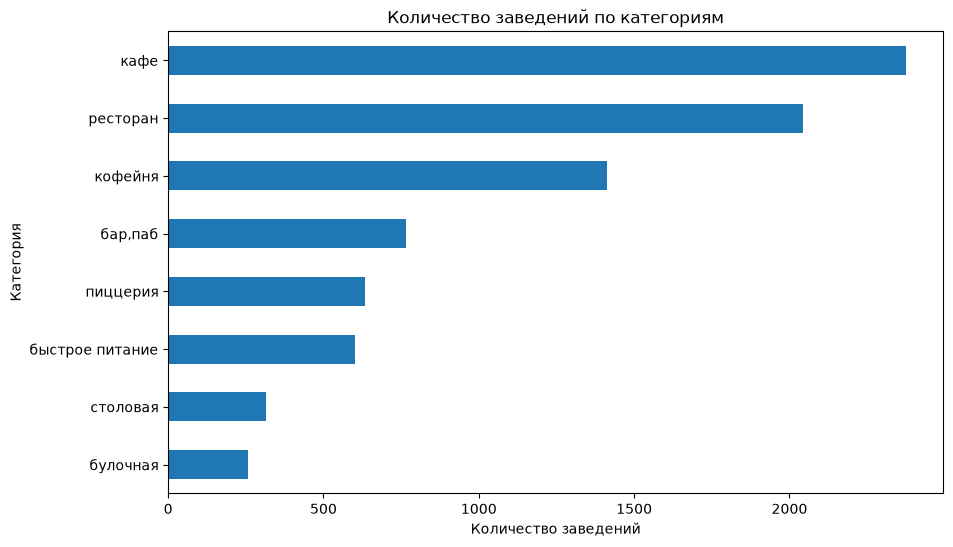

In [41]:
category_counts.sort_values().plot(
    kind='barh',
    figsize=(10, 6)
)

plt.title('Количество заведений по категориям')
plt.xlabel('Количество заведений')
plt.ylabel('Категория')
plt.show()

**В данных представлены 8 категорий заведений. Больше всего кафе - 2 376 заведений (28,28%), ресторанов - 2 042 (24,30%) и кофеен - 1 413 (16,82%). Эти три категории вместе составляют около 69% всех заведений. Меньше всего столовых - 315 (3,75%) и булочных - 256 (3,05%).**


---

### Задача 2

Изучаем распределение заведений по административным округам Москвы: определяем количество заведений в каждом округе и отдельно анализируем категории заведений в Центральном административном округе (ЦАО). Результаты представляем с помощью столбчатых диаграмм.

In [42]:
district_counts = df['district'].value_counts()
print(district_counts)

district
Центральный административный округ         2242
Северный административный округ             898
Южный административный округ                892
Северо-Восточный административный округ     890
Западный административный округ             850
Восточный административный округ            798
Юго-Восточный административный округ        714
Юго-Западный административный округ         709
Северо-Западный административный округ      409
Name: count, dtype: int64


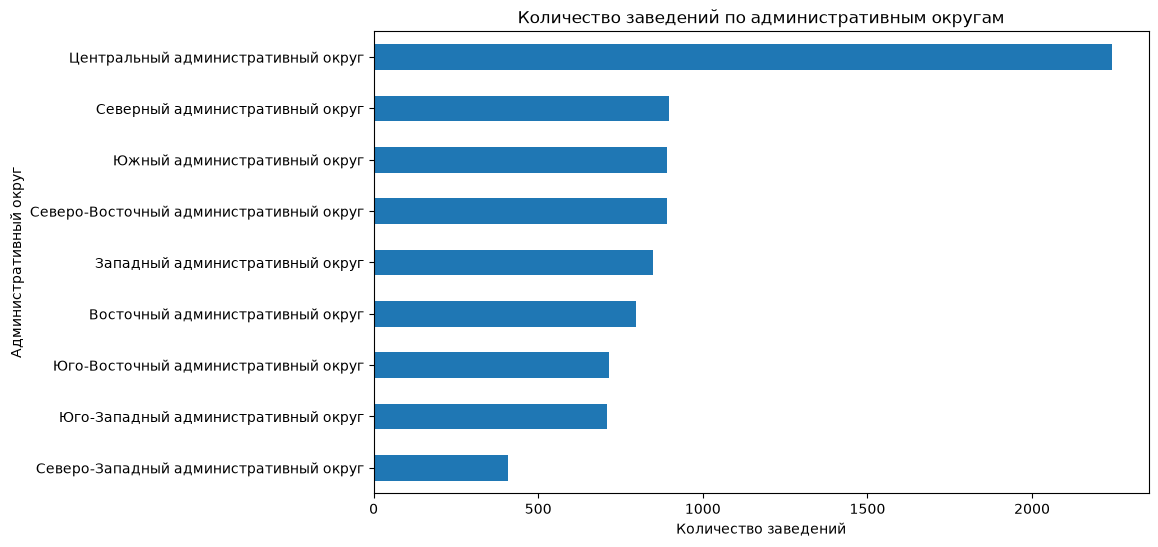

In [43]:
district_counts.sort_values().plot(
    kind='barh',
    figsize=(10, 6)
)

plt.title('Количество заведений по административным округам')
plt.xlabel('Количество заведений')
plt.ylabel('Административный округ')
plt.show()

**Больше всего заведений представлено в Центральном административном округе - 2 242.**

**Меньше всего в Северо-Западном - 409.** 

**ЦАО заметно лидирует по количеству заведений среди остальных округов.**

In [44]:
cao = df[df['district'] == 'Центральный административный округ']

cao_category_counts = cao['category'].value_counts()
print(cao_category_counts)

category
ресторан           670
кафе               464
кофейня            428
бар,паб            364
пиццерия           113
быстрое питание     87
столовая            66
булочная            50
Name: count, dtype: int64


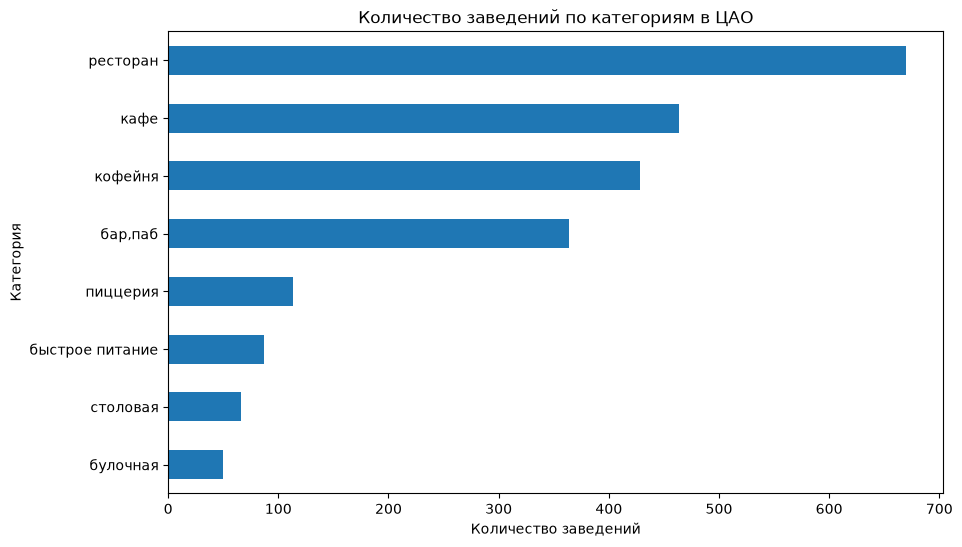

In [45]:
cao_category_counts.sort_values().plot(
    kind='barh',
    figsize=(10, 6)
)

plt.title('Количество заведений по категориям в ЦАО')
plt.xlabel('Количество заведений')
plt.ylabel('Категория')
plt.show()

Сравним доли основных категорий заведений в ЦАО и по всей Москве, чтобы понять, отличается ли структура рынка в центральном округе от общей структуры города.


In [46]:
category_share_moscow = df['category'].value_counts(normalize=True) * 100
category_share_cao = cao['category'].value_counts(normalize=True) * 100

category_share_comparison = pd.DataFrame({
    'Москва, %': category_share_moscow,
    'ЦАО, %': category_share_cao
}).round(2)

print('Доли категорий в Москве и ЦАО, %:')
print(category_share_comparison)

Доли категорий в Москве и ЦАО, %:
                 Москва, %  ЦАО, %
category                          
бар,паб               9.09   16.24
булочная              3.05    2.23
быстрое питание       7.18    3.88
кафе                 28.28   20.70
кофейня              16.82   19.09
пиццерия              7.53    5.04
ресторан             24.30   29.88
столовая              3.75    2.94


**Больше всего заведений представлено в Центральном административном округе - 2 242, меньше всего в Северо-Западном - 409. В ЦАО структура категорий отличается от структуры рынка Москвы в целом. Доля ресторанов в ЦАО составляет 29,88% против 24,30% по Москве, а доля баров и пабов - 16,24% против 9,09%. Доля кофеен также немного выше - 19,09% против 16,82%. При этом доля кафе в ЦАО ниже - 20,70% против 28,28% по Москве, как и доля заведений быстрого питания - 3,88% против 7,18%.**


---

### Задача 3

Изучаем соотношение сетевых и несетевых заведений в целом по датасету.

In [47]:
chain_counts = df['chain'].value_counts()

print(chain_counts)

chain
0    5199
1    3203
Name: count, dtype: int64


Для наглядного сравнения количества сетевых и несетевых заведений построим столбчатую диаграмму.


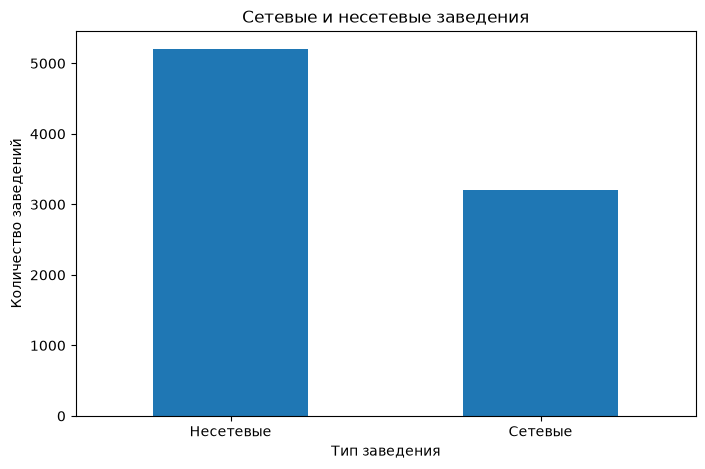

In [48]:
chain_counts.index = ['Несетевые', 'Сетевые']

chain_counts.plot(
    kind='bar',
    figsize=(8, 5)
)

plt.title('Сетевые и несетевые заведения')
plt.xlabel('Тип заведения')
plt.ylabel('Количество заведений')
plt.xticks(rotation=0)
plt.show()


Рассчитаем количество сетевых и несетевых заведений в каждой категории.

In [49]:
chain_category_counts = df.groupby('category')['chain'].value_counts().unstack(fill_value=0)

print(chain_category_counts)

chain               0    1
category                  
бар,паб           596  168
булочная           99  157
быстрое питание   371  232
кафе             1597  779
кофейня           693  720
пиццерия          303  330
ресторан         1313  729
столовая          227   88


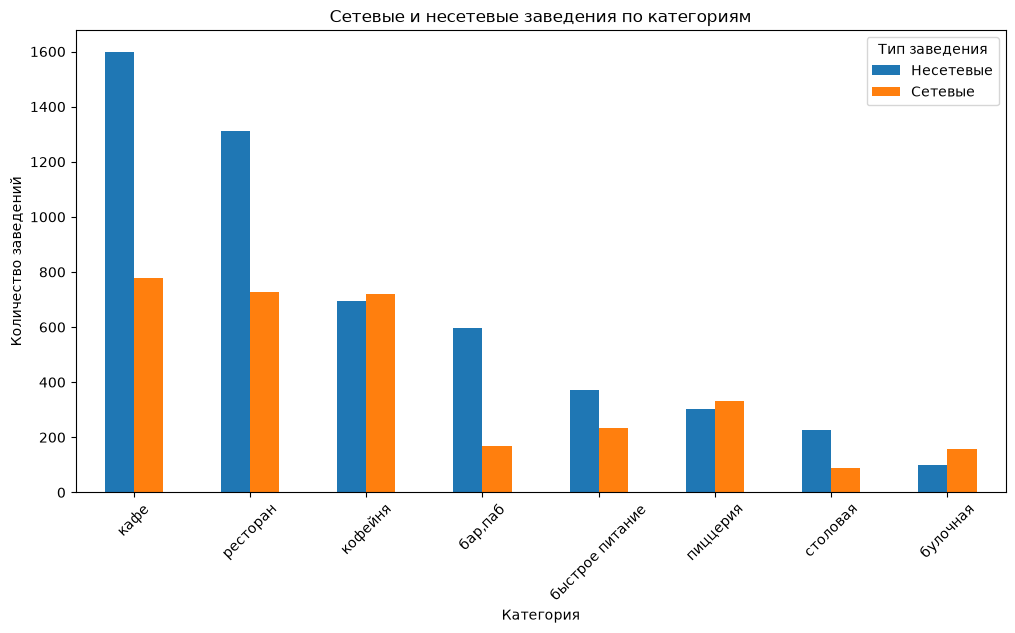

In [50]:
chain_category_counts.sort_values(by=0, ascending=False).plot(
    kind='bar',
    figsize=(12, 6)
)

plt.title('Сетевые и несетевые заведения по категориям')
plt.xlabel('Категория')
plt.ylabel('Количество заведений')
plt.xticks(rotation=45)
plt.legend(['Несетевые', 'Сетевые'], title='Тип заведения')
plt.show()

**Несетевых заведений больше - 5 199 (61,87%) против 3 203 сетевых (38,13%). По доле сетевых заведений внутри категории сетевые преобладают в булочных - 61,33%, пиццериях - 52,13% и кофейнях - 50,95%. Однако по абсолютному количеству сетевых заведений лидируют кафе - 779, рестораны - 729 и кофейни - 720. Поэтому булочные нельзя считать основным сегментом сетевого рынка только на основании их высокой доли сетевых заведений.**


---

### Задача 4

Изучаем распределение количества посадочных мест в заведениях и определяем основные статистические показатели.


In [51]:
print(df['seats'].describe())

count    4792.000000
mean      108.361436
std       122.841130
min         0.000000
25%        40.000000
50%        75.000000
75%       140.000000
max      1288.000000
Name: seats, dtype: float64


Дополнительно рассмотрим основные статистические показатели количества посадочных мест отдельно по категориям заведений.


In [52]:
seats_by_category = df.groupby('category')['seats'].describe()

print(seats_by_category)

                  count        mean         std  min   25%   50%    75%  \
category                                                                  
бар,паб           467.0  124.477516  145.162278  0.0  48.0  82.0  148.5   
булочная          148.0   89.385135   97.685844  0.0  25.0  50.0  120.0   
быстрое питание   349.0   98.891117  106.611739  0.0  28.0  65.0  140.0   
кафе             1217.0   97.365653  117.922464  0.0  35.0  60.0  120.0   
кофейня           751.0  111.199734  127.837772  0.0  40.0  80.0  144.0   
пиццерия          427.0   94.496487  112.282703  0.0  30.0  55.0  120.0   
ресторан         1269.0  121.892041  123.792216  0.0  48.0  86.0  150.0   
столовая          164.0   99.750000  122.951453  0.0  40.0  75.5  117.0   

                    max  
category                 
бар,паб          1288.0  
булочная          625.0  
быстрое питание  1040.0  
кафе             1288.0  
кофейня          1288.0  
пиццерия         1288.0  
ресторан         1288.0  
столовая       

**Количество посадочных мест сильно варьируется: медианное значение составляет 75 мест, среднее - 108. Максимальное значение - 1 288 мест. Разница между средним и медианой указывает на наличие заведений с очень большим количеством посадочных мест.**

Для наглядной оценки распределения количества посадочных мест построим гистограмму и диаграмму размаха. Гистограмма покажет основное распределение значений, а диаграмма размаха поможет выявить выбросы.


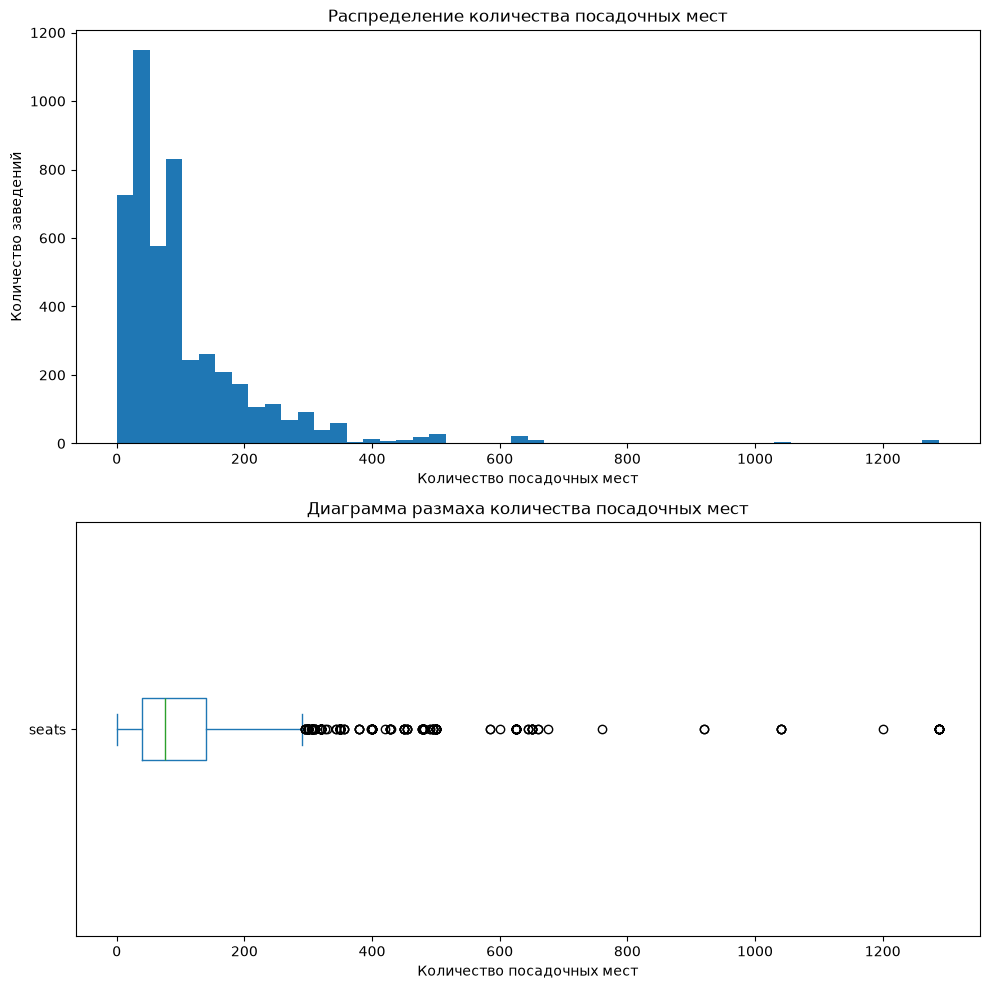

In [53]:
fig, axes = plt.subplots(2, 1, figsize=(10, 10))

df['seats'].plot(
    kind='hist',
    bins=50,
    ax=axes[0]
)

axes[0].set_title('Распределение количества посадочных мест')
axes[0].set_xlabel('Количество посадочных мест')
axes[0].set_ylabel('Количество заведений')

df['seats'].plot(
    kind='box',
    ax=axes[1],
    vert=False
)

axes[1].set_title('Диаграмма размаха количества посадочных мест')
axes[1].set_xlabel('Количество посадочных мест')
axes[1].set_ylabel('')

plt.tight_layout()
plt.show()

Посмотрим на заведения с наибольшим количеством посадочных мест, чтобы определить характер аномальных значений.

In [54]:
print(df[['name', 'category', 'seats']].sort_values('seats', ascending=False).head(10))

                    name  category   seats
6524           Ян Примус  ресторан  1288.0
6574              Мюнгер  пиццерия  1288.0
6518         DelonixCafe  ресторан  1288.0
6684     Пивной ресторан   бар,паб  1288.0
6690      Японская кухня  ресторан  1288.0
6641    One Price Coffee   кофейня  1288.0
6658              ГудБар   бар,паб  1288.0
6771               Точка      кафе  1288.0
6807  Loft-cafe академия      кафе  1288.0
6838  Alternative coffee   кофейня  1288.0


**В данных обнаружены аномальные значения: у заведений разных категорий количество посадочных мест достигает 1 288. Повторение одного и того же большого значения у разных заведений может быть связано с ошибкой или некорректным заполнением данных.**

Рассчитаем медианное количество посадочных мест для каждой категории заведений.

In [55]:
median_seats_by_category = df.groupby('category')['seats'].median()

print(median_seats_by_category)

category
бар,паб            82.0
булочная           50.0
быстрое питание    65.0
кафе               60.0
кофейня            80.0
пиццерия           55.0
ресторан           86.0
столовая           75.5
Name: seats, dtype: float64


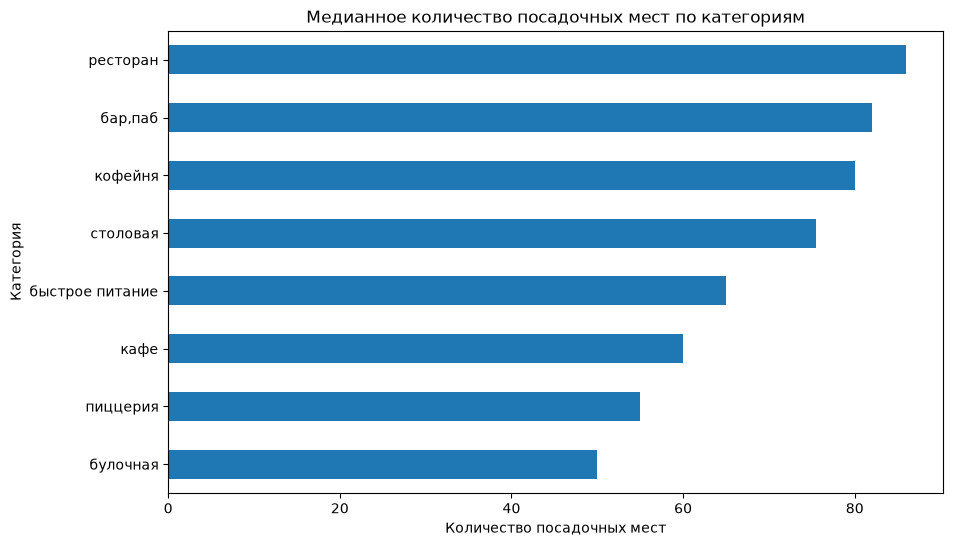

In [56]:
median_seats_by_category.sort_values().plot(
    kind='barh',
    figsize=(10, 6)
)

plt.title('Медианное количество посадочных мест по категориям')
plt.xlabel('Количество посадочных мест')
plt.ylabel('Категория')
plt.show()

**Наиболее типичное количество посадочных мест выше всего у ресторанов - 86, баров и пабов - 82,5 и кофеен - 80. Меньше всего мест обычно в булочных - 50, пиццериях - 55 и кафе - 60.**

**Промежуточный вывод**

**Количество посадочных мест сильно варьируется: медианное значение составляет 75 мест, среднее - 108, максимальное - 1 288. Значение 1 288 встречается у заведений разных категорий и, вероятно, связано с ошибкой или некорректным заполнением данных.**

**Наиболее типичное количество мест выше всего у ресторанов - 86, баров и пабов - 82,5 и кофеен - 80. Меньше всего мест обычно в булочных - 50, пиццериях - 55 и кафе - 60. Для оценки типичного количества мест использовали медиану, так как она меньше подвержена влиянию выбросов.**

---

### Задача 5

Изучаем средний рейтинг заведений по категориям и сравниваем его между разными типами общепита.

In [57]:
mean_rating_by_category = df.groupby('category')['rating'].mean()

print(mean_rating_by_category)

category
бар,паб            4.387696
булочная           4.268359
быстрое питание    4.050249
кафе               4.124285
кофейня            4.277282
пиццерия           4.301264
ресторан           4.290402
столовая           4.211429
Name: rating, dtype: float64


Для корректного сравнения среднего рейтинга построим два графика. Первый покажет значения в полном диапазоне рейтинга от 0 до 5, а второй - тот же показатель в увеличенном диапазоне от 4 до 4,4, чтобы лучше увидеть небольшие различия между категориями.


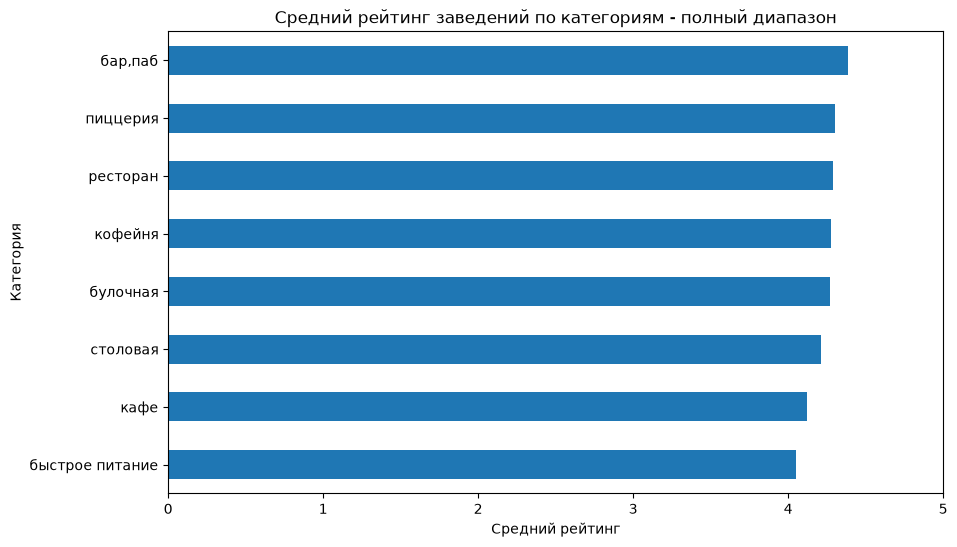

In [58]:
mean_rating_by_category.sort_values().plot(
    kind='barh',
    figsize=(10, 6),
    xlim=(0, 5)
)

plt.title('Средний рейтинг заведений по категориям - полный диапазон')
plt.xlabel('Средний рейтинг')
plt.ylabel('Категория')
plt.show()

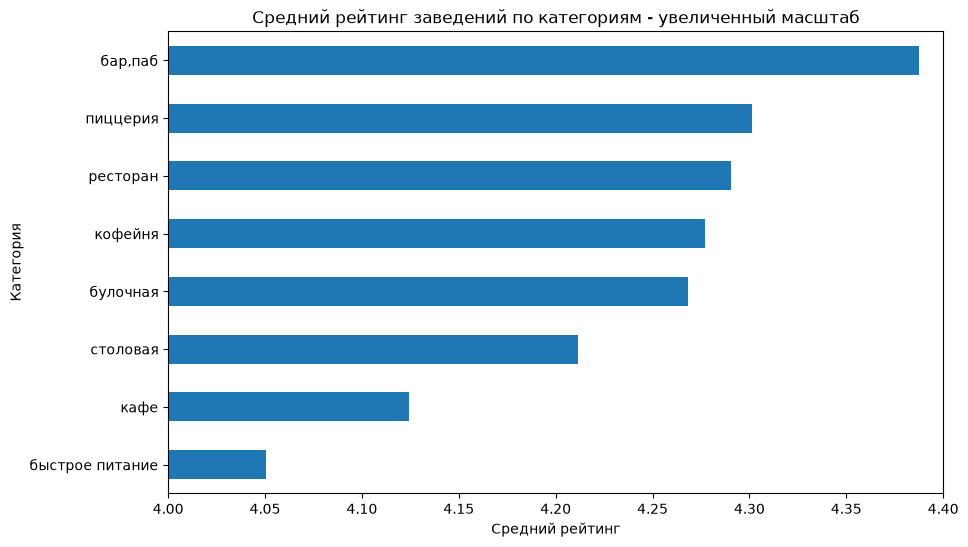

In [59]:
mean_rating_by_category.sort_values().plot(
    kind='barh',
    figsize=(10, 6),
    xlim=(4, 4.4)
)

plt.title('Средний рейтинг заведений по категориям - увеличенный масштаб')
plt.xlabel('Средний рейтинг')
plt.ylabel('Категория')
plt.show()

**Средние рейтинги различаются от 4,05 до 4,39. Самый высокий средний рейтинг у баров и пабов - 4,39, самый низкий у заведений быстрого питания - 4,05. Разница составляет 0,34 пункта. При этом небольшая разница в среднем рейтинге может иметь существенное значение для бизнеса, поскольку повышение рейтинга требует времени и ресурсов. Поэтому рейтинг важно рассматривать не только как числовой показатель, но и как результат качества сервиса и работы заведения.**


---

### Задача 6

Рассчитаем корреляцию рейтинга с основными признаками заведений с помощью коэффициента `phi_k`.

In [60]:
corr_matrix = df[
    ['rating', 'category', 'district', 'chain', 'seats', 'price', 'is_24_7']
].phik_matrix()

print(corr_matrix)

interval columns not set, guessing: ['rating', 'chain', 'seats']
            rating  category  district     chain     seats     price   is_24_7
rating    1.000000  0.189716  0.200761  0.107833  0.000000  0.281253  0.150365
category  0.189716  1.000000  0.174584  0.266000  0.048923  0.329690  0.244815
district  0.200761  0.174584  1.000000  0.064473  0.352440  0.203032  0.076357
chain     0.107833  0.266000  0.064473  1.000000  0.056523  0.088834  0.043488
seats     0.000000  0.048923  0.352440  0.056523  1.000000  0.020128  0.043193
price     0.281253  0.329690  0.203032  0.088834  0.020128  1.000000  0.063702
is_24_7   0.150365  0.244815  0.076357  0.043488  0.043193  0.063702  1.000000


Для наглядного сравнения коэффициентов построим тепловую карту корреляционной матрицы. Она позволит быстро оценить силу взаимосвязей между рейтингом и остальными признаками.


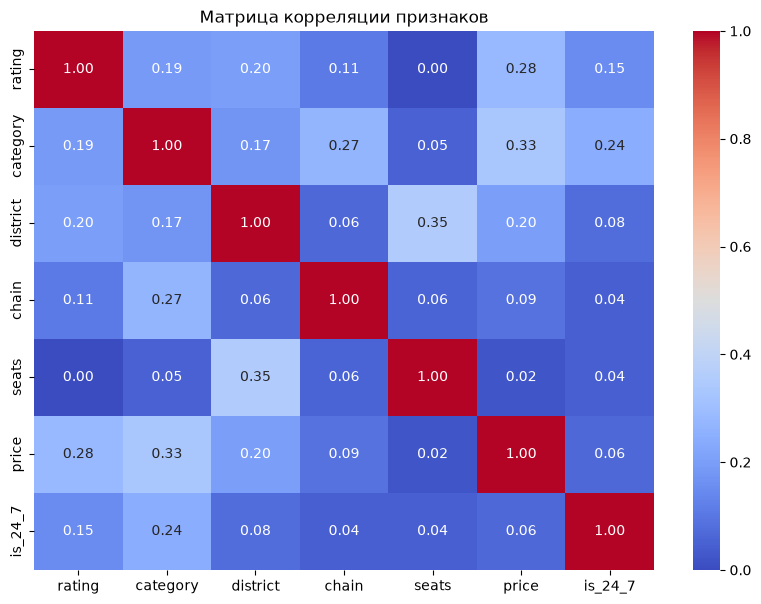

In [61]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm'
)

plt.title('Матрица корреляции признаков')
plt.show()

Сравним средний рейтинг заведений в разных ценовых категориях, чтобы проверить связь рейтинга с ценовой категорией.

In [62]:
rating_by_price = df.groupby('price')['rating'].mean()

print(rating_by_price)

price
Нет информации    4.166778
высокие           4.436611
выше среднего     4.386348
низкие            4.173077
средние           4.297874
Name: rating, dtype: float64


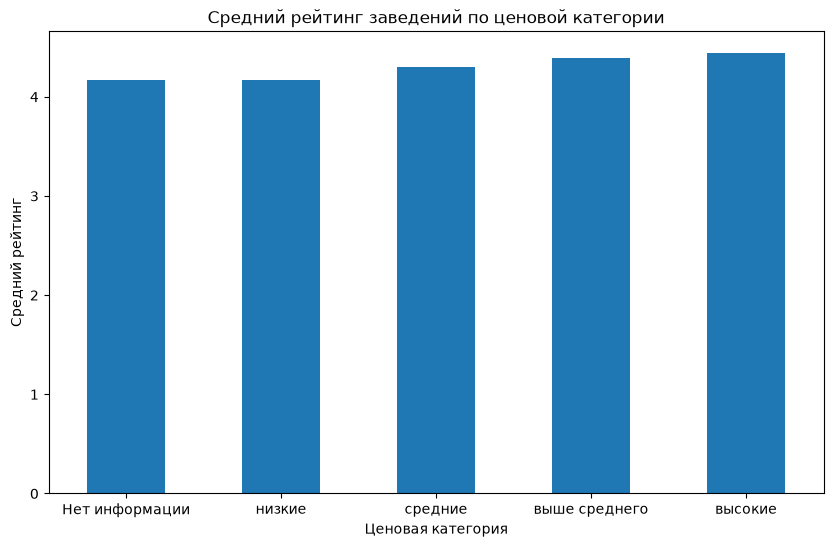

In [63]:
rating_by_price.sort_values().plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title('Средний рейтинг заведений по ценовой категории')
plt.xlabel('Ценовая категория')
plt.ylabel('Средний рейтинг')
plt.xticks(rotation=0)
plt.show()

Проверим, насколько равномерно ценовые категории представлены внутри разных категорий заведений. Для этого построим таблицу сопряжённости и посмотрим, есть ли ценовые сегменты с очень малым количеством заведений или отсутствующие полностью.


In [64]:
price_category_crosstab = pd.crosstab(
    df['category'],
    df['price']
)

print(price_category_crosstab)

price            Нет информации  высокие  выше среднего  низкие  средние
category                                                                
бар,паб                     270      121            153       2      218
булочная                    215        6              4       3       28
быстрое питание             413        3              5      22      160
кафе                       1743       30             78      26      499
кофейня                     937       17             14      68      377
пиццерия                    322       30             40       4      237
ресторан                   1025      270            268      21      458
столовая                    162        1              2      10      140


Поскольку количество заведений разных категорий сильно различается, дополнительно рассчитаем доли ценовых категорий внутри каждого типа заведения.


In [65]:
price_category_share = pd.crosstab(
    df['category'],
    df['price'],
    normalize='index'
) * 100

print(price_category_share.round(2))

price            Нет информации  высокие  выше среднего  низкие  средние
category                                                                
бар,паб                   35.34    15.84          20.03    0.26    28.53
булочная                  83.98     2.34           1.56    1.17    10.94
быстрое питание           68.49     0.50           0.83    3.65    26.53
кафе                      73.36     1.26           3.28    1.09    21.00
кофейня                   66.31     1.20           0.99    4.81    26.68
пиццерия                  50.87     4.74           6.32    0.63    37.44
ресторан                  50.20    13.22          13.12    1.03    22.43
столовая                  51.43     0.32           0.63    3.17    44.44


**Средний рейтинг различается между ценовыми категориями, однако по этим данным нельзя сделать вывод, что более высокая цена связана с более высоким рейтингом. Ценовые категории представлены внутри разных типов заведений очень неравномерно, а доля значений `Нет информации` в `price` высока. Например, у булочных 83,98% значений `price` имеют значение `Нет информации`, у кафе - 73,36%, у кофеен - 66,31%. В отдельных сочетаниях категории и цены наблюдений очень мало, поэтому сравнение может быть нестабильным. Таким образом, выявленная корреляция `phi_k ≈ 0,28` показывает наличие связи между признаками, но не позволяет считать её прямой зависимостью рейтинга от цены.**



---

### Задача 7

Сгруппируем данные по названиям заведений и определим топ-15 популярных сетей в Москве. Для них рассчитаем средний рейтинг и определим категории заведений. Результаты представим с помощью подходящих визуализаций.

Сначала определим топ-15 сетей по количеству заведений в Москве.

In [66]:
chain_counts = (
    df[df['chain'] == 1]['name']
    .value_counts()
    .head(15)
)

print(chain_counts)

name
Шоколадница                            120
Домино'с Пицца                          76
Додо Пицца                              74
One Price Coffee                        71
Яндекс Лавка                            69
Cofix                                   65
Prime                                   50
Хинкальная                              44
КОФЕПОРТ                                42
Кулинарная лавка братьев Караваевых     39
Теремок                                 38
Чайхана                                 37
Буханка                                 32
CofeFest                                32
Му-Му                                   27
Name: count, dtype: int64


**Сохраним названия топ-15 сетей, чтобы использовать их для дальнейшего анализа.**

In [67]:
top_15_names = chain_counts.index

Рассчитаем средний рейтинг для каждой сети из топ-15.

In [68]:
top_15 = chain_counts.reset_index()
top_15.columns = ['name', 'count']

top_15_rating = (
    df[
        (df['chain'] == 1) &
        (df['name'].isin(top_15['name']))
    ]
    .groupby('name')['rating']
    .mean()
    .sort_values(ascending=False)
)

print(top_15_rating)

name
Буханка                                4.396875
Кулинарная лавка братьев Караваевых    4.394872
Хинкальная                             4.322727
Додо Пицца                             4.286486
Му-Му                                  4.229630
Шоколадница                            4.177500
Домино'с Пицца                         4.169737
КОФЕПОРТ                               4.147619
Теремок                                4.123684
Prime                                  4.116000
Cofix                                  4.075385
One Price Coffee                       4.064789
CofeFest                               3.984375
Чайхана                                3.924324
Яндекс Лавка                           3.872464
Name: rating, dtype: float64


Определим категорию каждой сети из топ-15 по наиболее часто встречающейся категории заведений.

In [69]:
top_15_category = (
    df.merge(top_15[['name']], on='name', how='inner')
    .groupby(['name', 'category'])['rating']
    .count()
    .reset_index()
    .sort_values(['name', 'rating'], ascending=[True, False])
    .drop_duplicates('name')
)

print(top_15_category)

                                   name  category  rating
1                              CofeFest   кофейня      31
2                                 Cofix   кофейня      65
3                      One Price Coffee   кофейня      71
5                                 Prime  ресторан      49
6                               Буханка  булочная      25
9                            Додо Пицца  пиццерия      74
10                       Домино'с Пицца  пиццерия      76
11                             КОФЕПОРТ   кофейня      42
12  Кулинарная лавка братьев Караваевых      кафе      39
15                                Му-Му      кафе      12
21                              Теремок  ресторан      36
24                           Хинкальная      кафе      19
28                              Чайхана      кафе      26
31                          Шоколадница   кофейня     119
32                         Яндекс Лавка  ресторан      69


Объединим количество заведений, средний рейтинг и категорию для каждой сети в одну таблицу.

In [70]:
top_15_result = top_15.merge(
    top_15_rating.reset_index(),
    on='name'
).merge(
    top_15_category[['name', 'category']],
    on='name'
)

print(top_15_result)

                                   name  count    rating  category
0                           Шоколадница    120  4.177500   кофейня
1                        Домино'с Пицца     76  4.169737  пиццерия
2                            Додо Пицца     74  4.286486  пиццерия
3                      One Price Coffee     71  4.064789   кофейня
4                          Яндекс Лавка     69  3.872464  ресторан
5                                 Cofix     65  4.075385   кофейня
6                                 Prime     50  4.116000  ресторан
7                            Хинкальная     44  4.322727      кафе
8                              КОФЕПОРТ     42  4.147619   кофейня
9   Кулинарная лавка братьев Караваевых     39  4.394872      кафе
10                              Теремок     38  4.123684  ресторан
11                              Чайхана     37  3.924324      кафе
12                              Буханка     32  4.396875  булочная
13                             CofeFest     32  3.984375   коф

Визуализируем топ-15 популярных сетей по количеству заведений в Москве.

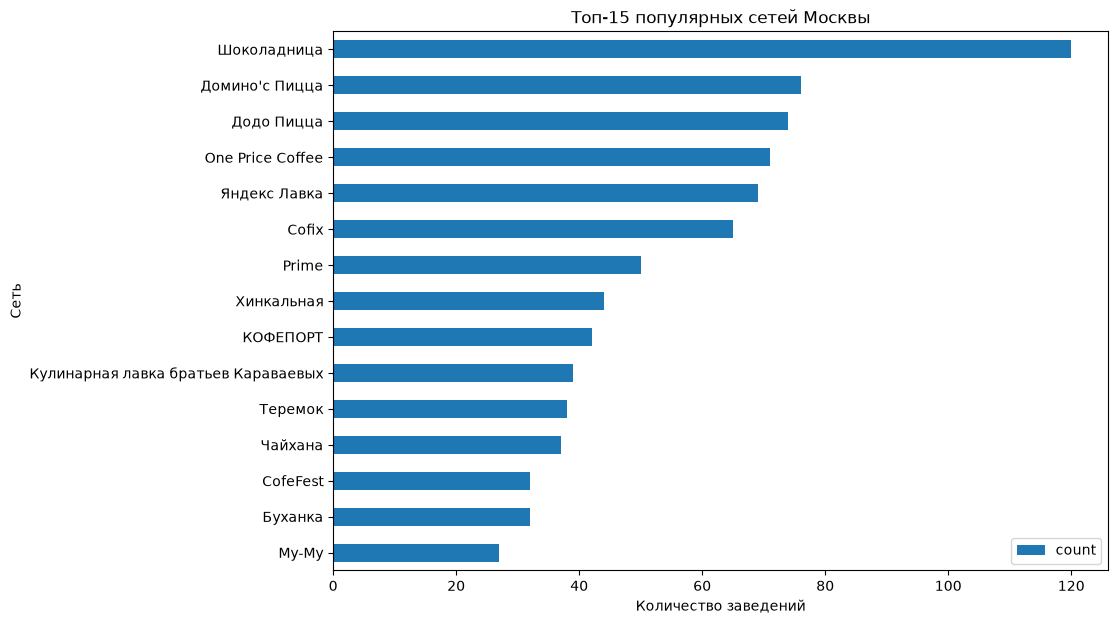

In [71]:
top_15_result.sort_values('count').plot(
    kind='barh',
    x='name',
    y='count',
    figsize=(10, 7)
)

plt.title('Топ-15 популярных сетей Москвы')
plt.xlabel('Количество заведений')
plt.ylabel('Сеть')
plt.show()

Сравним средний рейтинг популярных сетей.

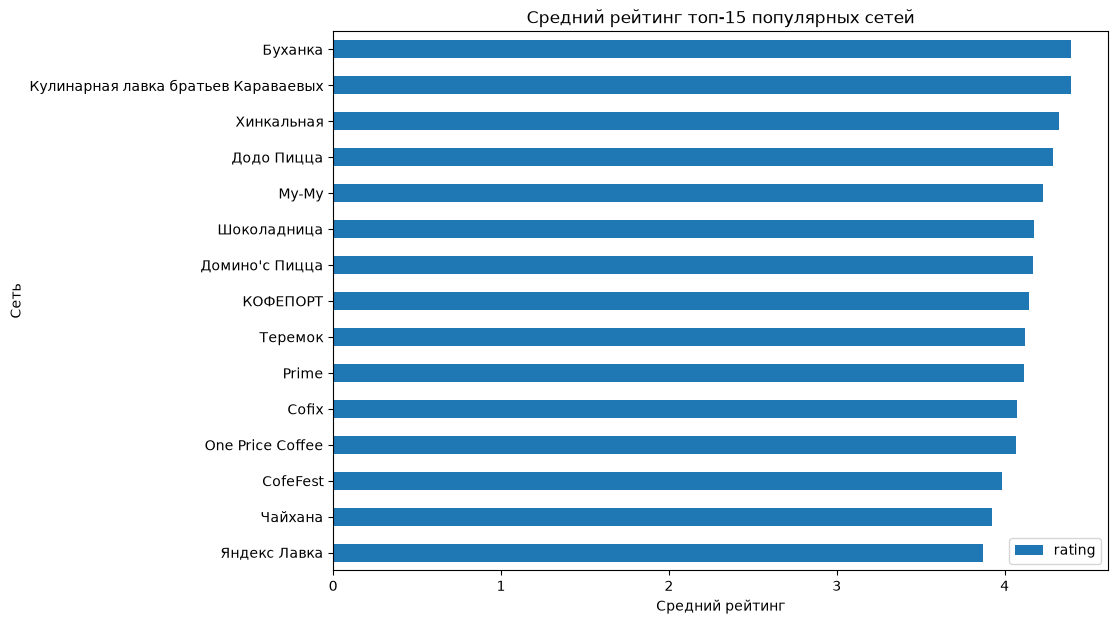

In [72]:
top_15_result.sort_values('rating').plot(
    kind='barh',
    x='name',
    y='rating',
    figsize=(10, 7)
)

plt.title('Средний рейтинг топ-15 популярных сетей')
plt.xlabel('Средний рейтинг')
plt.ylabel('Сеть')
plt.show()

Определим распределение топ-15 популярных сетей по категориям.

In [73]:
category_counts_top_15 = (
    top_15_result
    .groupby('category')['count']
    .sum()
    .sort_values(ascending=False)
)

category_share_top_15 = (
    category_counts_top_15 / category_counts_top_15.sum() * 100
).round(2)

print('Количество точек топ-15 сетей по категориям:')
print(category_counts_top_15)

print('\nДоля точек топ-15 сетей по категориям, %:')
print(category_share_top_15)

Количество точек топ-15 сетей по категориям:
category
кофейня     330
ресторан    157
пиццерия    150
кафе        147
булочная     32
Name: count, dtype: int64

Доля точек топ-15 сетей по категориям, %:
category
кофейня     40.44
ресторан    19.24
пиццерия    18.38
кафе        18.01
булочная     3.92
Name: count, dtype: float64


Визуализируем распределение топ-15 популярных сетей по категориям.

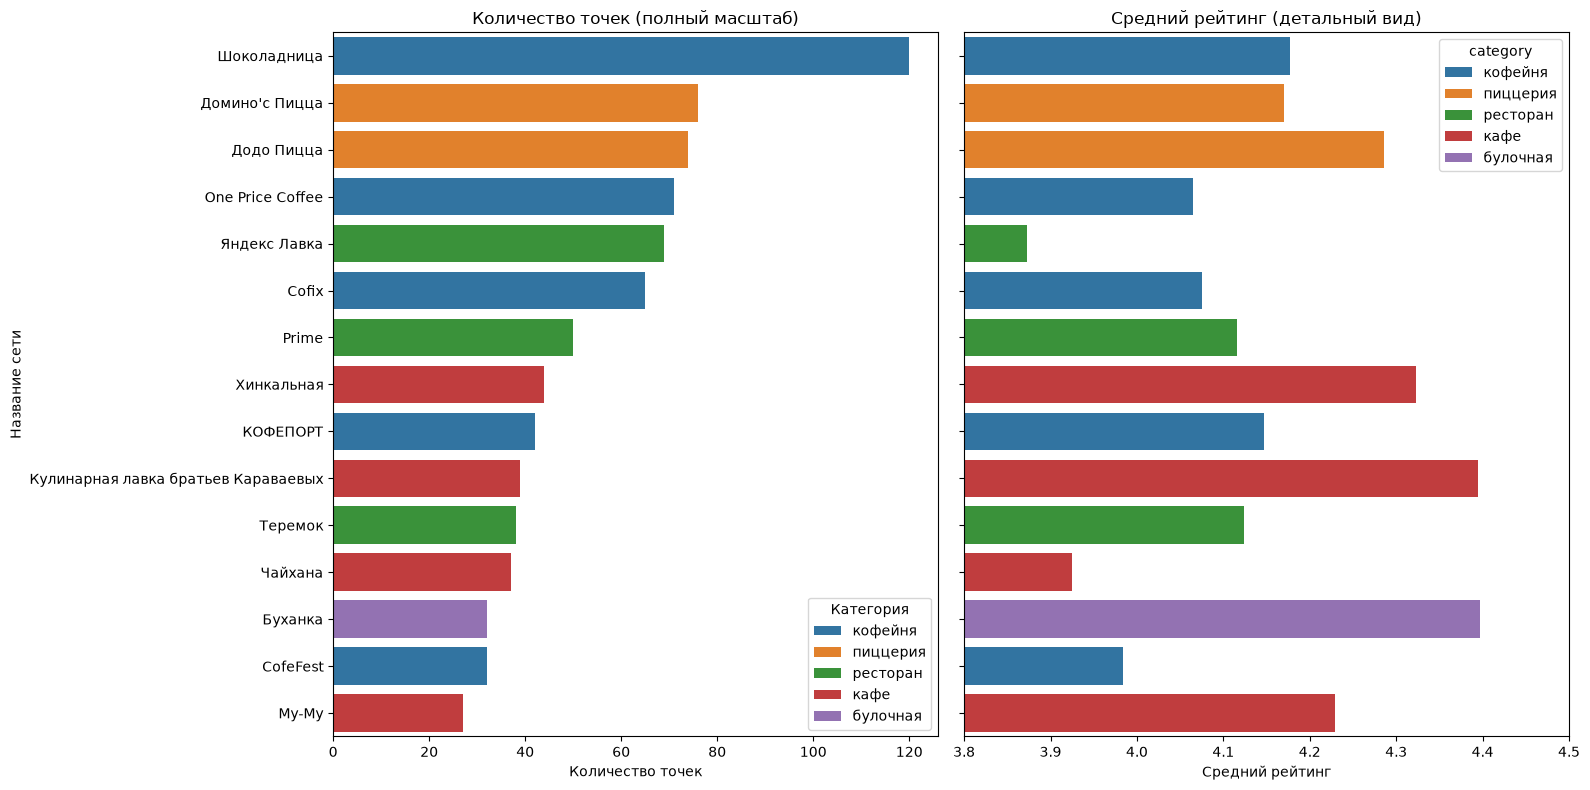

In [74]:
fig, axes = plt.subplots(1, 2, figsize=(16, 8), sharey=True)

plot_data = top_15_result.sort_values('count', ascending=False)

# Количество точек
sns.barplot(
    data=plot_data,
    x='count',
    y='name',
    hue='category',
    ax=axes[0]
)

axes[0].set_title('Количество точек (полный масштаб)')
axes[0].set_xlabel('Количество точек')
axes[0].set_ylabel('Название сети')
axes[0].legend(title='Категория')

# for container in axes[0].containers:
#     axes[0].bar_label(container, fmt='%.0f', padding=3)

# Средний рейтинг
sns.barplot(
    data=plot_data,
    x='rating',
    y='name',
    hue='category',
    ax=axes[1],
#     legend=False
)

axes[1].set_title('Средний рейтинг (детальный вид)')
axes[1].set_xlabel('Средний рейтинг')
axes[1].set_ylabel('')

axes[1].set_xlim(3.8, 4.5)

# for container in axes[1].containers:
#     axes[1].bar_label(container, fmt='%.2f', padding=3)

plt.tight_layout()
plt.show()

Выведем итоговую информацию по топ-15 популярных сетей: количество точек, средний рейтинг и категорию заведения.


In [75]:
print(top_15_result)

                                   name  count    rating  category
0                           Шоколадница    120  4.177500   кофейня
1                        Домино'с Пицца     76  4.169737  пиццерия
2                            Додо Пицца     74  4.286486  пиццерия
3                      One Price Coffee     71  4.064789   кофейня
4                          Яндекс Лавка     69  3.872464  ресторан
5                                 Cofix     65  4.075385   кофейня
6                                 Prime     50  4.116000  ресторан
7                            Хинкальная     44  4.322727      кафе
8                              КОФЕПОРТ     42  4.147619   кофейня
9   Кулинарная лавка братьев Караваевых     39  4.394872      кафе
10                              Теремок     38  4.123684  ресторан
11                              Чайхана     37  3.924324      кафе
12                              Буханка     32  4.396875  булочная
13                             CofeFest     32  3.984375   коф

Определим распределение точек топ-15 популярных сетей по категориям и рассчитаем долю каждой категории.


In [76]:
print('Количество точек топ-15 сетей по категориям:')
print(category_counts_top_15)

print('\nДоля точек топ-15 сетей по категориям, %:')
print(category_share_top_15)

Количество точек топ-15 сетей по категориям:
category
кофейня     330
ресторан    157
пиццерия    150
кафе        147
булочная     32
Name: count, dtype: int64

Доля точек топ-15 сетей по категориям, %:
category
кофейня     40.44
ресторан    19.24
пиццерия    18.38
кафе        18.01
булочная     3.92
Name: count, dtype: float64


**В топ-15 популярных сетей вошли заведения пяти категорий. По количеству точек среди них лидируют кофейни - 330 точек (40,44%), рестораны - 157 (19,24%), пиццерии - 150 (18,38%) и кафе - 147 (18,01%). Булочные представлены 32 точками (3,92%).**

**По количеству точек лидируют «Шоколадница» - 120, «Домино'с Пицца» - 76 и «Додо Пицца» - 74. Средний рейтинг топ-15 сетей находится в диапазоне от 3,87 до 4,40. Самый высокий средний рейтинг у «Буханки» - 4,40, самый низкий - у «Яндекс Лавки» - 3,87.**



---

### Задача 8

Изучим, как средний чек заведений (`middle_avg_bill`) различается между административными округами Москвы. Отдельно сравним цены в ЦАО и остальных округах и проверим, как удалённость от центра связана со стоимостью среднего чека. Результаты представим с помощью подходящих визуализаций.


Изучим вариацию среднего чека по административным округам Москвы и сравним ЦАО с остальными округами.

In [77]:
median_bill_by_district = df.groupby('district')['middle_avg_bill'].median().sort_values()

print(median_bill_by_district)

district
Юго-Восточный административный округ        450.0
Северо-Восточный административный округ     500.0
Южный административный округ                500.0
Восточный административный округ            575.0
Юго-Западный административный округ         600.0
Северный административный округ             650.0
Северо-Западный административный округ      700.0
Западный административный округ            1000.0
Центральный административный округ         1000.0
Name: middle_avg_bill, dtype: float64


Сравним медианный средний чек заведений по административным округам.

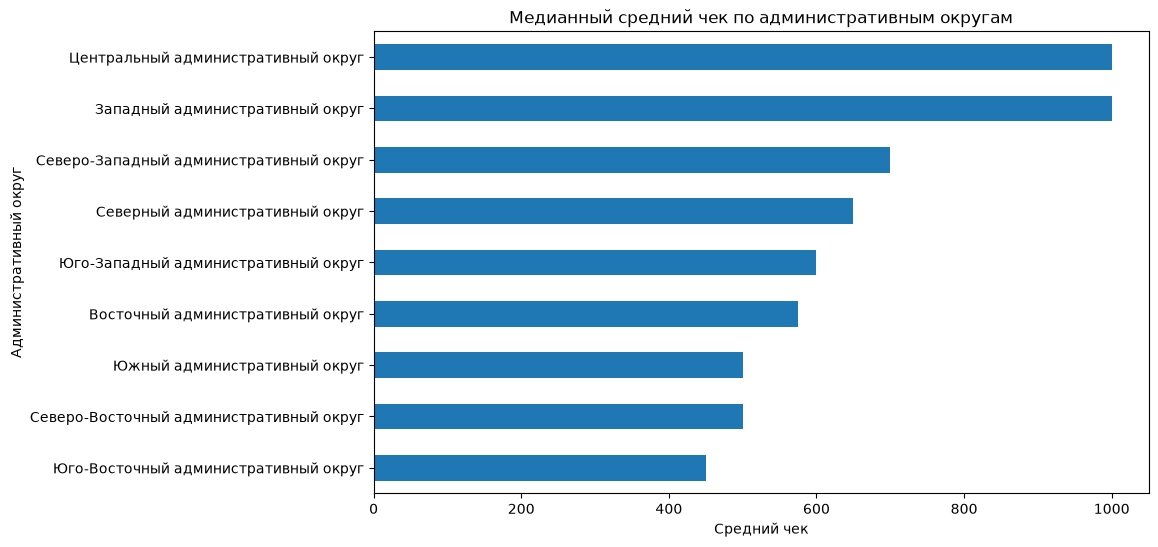

In [78]:
median_bill_by_district.plot(
    kind='barh',
    figsize=(10, 6)
)

plt.title('Медианный средний чек по административным округам')
plt.xlabel('Средний чек')
plt.ylabel('Административный округ')
plt.show()

**ЦАО и Западный административный округ имеют самый высокий медианный средний чек - 1 000, а самый низкий показатель в Юго-Восточном административном округе - 450.**

Сравним медианный средний чек в ЦАО и остальных административных округах Москвы.

In [79]:
cao_bill = df[df['district'] == 'Центральный административный округ']['middle_avg_bill'].median()
other_bill = df[df['district'] != 'Центральный административный округ']['middle_avg_bill'].median()

print('ЦАО:', cao_bill)
print('Остальные округа:', other_bill)

ЦАО: 1000.0
Остальные округа: 600.0


**Медианный средний чек в ЦАО составляет 1 000, а в остальных административных округах - 600. Таким образом, в ЦАО медианный чек значительно выше.**

Сравним медианный средний чек по административным округам, чтобы оценить изменение цен в зависимости от расположения округа относительно центра Москвы.

In [80]:
district_order = [
    'Центральный административный округ',
    'Западный административный округ',
    'Северный административный округ',
    'Северо-Восточный административный округ',
    'Восточный административный округ',
    'Юго-Западный административный округ',
    'Северо-Западный административный округ',
    'Южный административный округ',
    'Юго-Восточный административный округ'
]

median_bill_ordered = median_bill_by_district.reindex(district_order)

print(median_bill_ordered)

district
Центральный административный округ         1000.0
Западный административный округ            1000.0
Северный административный округ             650.0
Северо-Восточный административный округ     500.0
Восточный административный округ            575.0
Юго-Западный административный округ         600.0
Северо-Западный административный округ      700.0
Южный административный округ                500.0
Юго-Восточный административный округ        450.0
Name: middle_avg_bill, dtype: float64


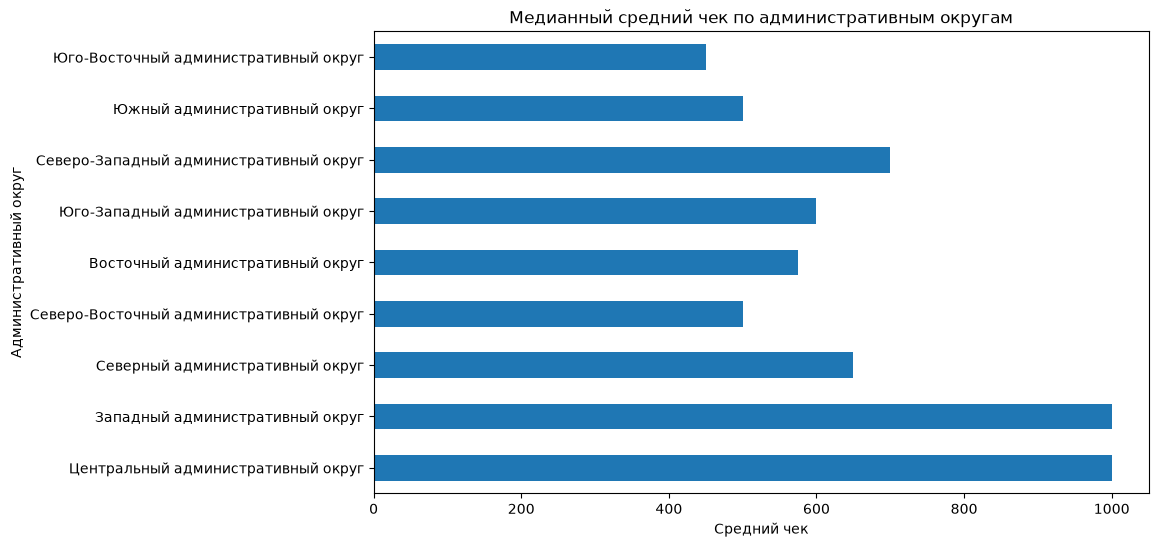

In [81]:
median_bill_ordered.plot(
    kind='barh',
    figsize=(10, 6)
)

plt.title('Медианный средний чек по административным округам')
plt.xlabel('Средний чек')
plt.ylabel('Административный округ')
plt.show()

Сначала сравним распределение категорий заведений в ЦАО и остальных административных округах. Это необходимо, поскольку различия в среднем чеке могут объясняться не только расположением, но и разным составом заведений.


In [82]:
category_share_cao_other = pd.DataFrame({
    'ЦАО, %': cao['category'].value_counts(normalize=True) * 100,
    'Остальные округа, %': df[df['district'] != 'Центральный административный округ']['category'].value_counts(normalize=True) * 100
}).round(2)

print('Доли категорий в ЦАО и остальных округах, %:')
print(category_share_cao_other)

Доли категорий в ЦАО и остальных округах, %:
                 ЦАО, %  Остальные округа, %
category                                    
бар,паб           16.24                 6.49
булочная           2.23                 3.34
быстрое питание    3.88                 8.38
кафе              20.70                31.04
кофейня           19.09                15.99
пиццерия           5.04                 8.44
ресторан          29.88                22.27
столовая           2.94                 4.04


Чтобы отделить влияние расположения от влияния категории заведения, сравним медианный средний чек ресторанов в разных административных округах.


In [83]:
restaurant_bill_by_district = (
    df[df['category'] == 'ресторан']
    .groupby('district')['middle_avg_bill']
    .agg(['median', 'count'])
    .sort_values('median')
)

print('Медианный средний чек ресторанов по административным округам:')
print(restaurant_bill_by_district)

Медианный средний чек ресторанов по административным округам:
                                         median  count
district                                              
Северо-Восточный административный округ   837.5     84
Юго-Восточный административный округ      925.0     54
Южный административный округ              975.0     90
Восточный административный округ         1000.0     68
Юго-Западный административный округ      1050.0     78
Северный административный округ          1187.5     96
Северо-Западный административный округ   1250.0     48
Центральный административный округ       1250.0    406
Западный административный округ          1300.0    116


Проверим количество заведений с заполненным средним чеком. Это позволит оценить, насколько полно представлены данные и насколько надёжно можно сравнивать округа между собой.


In [84]:
bill_data_by_district = (
    df.groupby('district')['middle_avg_bill']
    .agg(
        всего_заведений='size',
        заполнено='count'
    )
)

bill_data_by_district['доля_заполненных, %'] = (
    bill_data_by_district['заполнено'] /
    bill_data_by_district['всего_заведений'] * 100
).round(2)

print('Заполненность данных о среднем чеке по административным округам:')
print(bill_data_by_district)

Заполненность данных о среднем чеке по административным округам:
                                         всего_заведений  заполнено  \
district                                                              
Восточный административный округ                     798        260   
Западный административный округ                      850        306   
Северный административный округ                      898        322   
Северо-Восточный административный округ              890        301   
Северо-Западный административный округ               409        157   
Центральный административный округ                  2242       1060   
Юго-Восточный административный округ                 714        194   
Юго-Западный административный округ                  709        235   
Южный административный округ                         892        314   

                                         доля_заполненных, %  
district                                                      
Восточный административный 

**Медианный средний чек заметно различается между административными округами Москвы. Самые высокие значения наблюдаются в ЦАО и Западном административном округе - по 1 000, а самый низкий показатель в Юго-Восточном административном округе - 450. В ЦАО медианный чек составляет 1 000 против 600 в остальных округах.**

**При этом структура рынка в ЦАО и остальных округах различается: в ЦАО выше доля ресторанов - 29,88% против 22,27%, а также баров и пабов - 16,24% против 6,49%. В остальных округах выше доля кафе - 31,04% против 20,70%, быстрого питания - 8,38% против 3,88% и пиццерий - 8,44% против 5,04%. Поэтому часть различий в среднем чеке может объясняться разным составом категорий.**

**Сравнение ресторанов показывает, что их медианный средний чек также различается между округами: от 837,5 в Северо-Восточном округе до 1 300 в Западном и 1 250 в ЦАО. Это указывает на то, что различия в ценах сохраняются и внутри одной категории, поэтому расположение может быть связано с уровнем цен. Однако точное влияние удалённости от центра определить нельзя, поскольку в датасете нет признака расстояния до центра.**

**При интерпретации результатов необходимо учитывать разреженность данных. Средний чек заполнен только для 27,17-47,28% заведений в разных округах. В ЦАО доля заполненных значений выше - 47,28%, а в Юго-Восточном округе ниже - 27,17%. Поэтому полученные медианы рассчитаны только по заведениям с указанным средним чеком и могут не полностью отражать рынок каждого округа.**


---

### Промежуточный вывод

В ходе исследовательского анализа изучили категории заведений, их распределение по административным округам, сетевой статус, количество посадочных мест, рейтинги, взаимосвязи рейтинга с другими признаками, популярные сети и средний чек.

На рынке Москвы преобладают кафе, рестораны и кофейни. Больше всего заведений находится в ЦАО - 2 242.

Большинство заведений являются несетевыми - 5 199 против 3 203 сетевых. При этом среди кофеен, пиццерий и булочных сетевые заведения составляют более половины точек соответствующей категории.

Средние рейтинги заведений по категориям находятся в диапазоне от 4,05 до 4,39. Самый высокий средний рейтинг у баров и пабов - 4,39, самый низкий у заведений быстрого питания - 4,05. Наиболее сильная связь рейтинга среди рассмотренных признаков наблюдается с ценовой категорией (`phi_k = 0,28`), однако её нельзя трактовать как прямую зависимость рейтинга от цены из-за неравномерного распределения ценовых категорий и большого количества пропусков.

В топ-15 популярных сетей по количеству точек лидируют «Шоколадница» - 120, «Домино'с Пицца» - 76 и «Додо Пицца» - 74. По количеству точек среди топ-15 сетей преобладают кофейни - 330 точек (40,44%). Средний рейтинг топ-15 сетей находится в диапазоне от 3,87 до 4,40.

Медианный средний чек в ЦАО составляет 1 000 против 600 в остальных округах. При этом структура категорий в ЦАО и остальных округах различается, поэтому часть разницы в среднем чеке может объясняться составом рынка. Внутри одной категории - ресторанов - медианный чек также различается между округами: от 837,5 до 1 300. Это позволяет предположить наличие связи между расположением и уровнем цен, но точное влияние удалённости от центра определить нельзя, поскольку в данных нет признака расстояния до центра.

Дополнительно необходимо учитывать разреженность данных о среднем чеке: доля заполненных значений по округам составляет только 27,17-47,28%. Поэтому расчёты среднего чека основаны не на всех заведениях и требуют осторожной интерпретации.

**Таким образом, при выборе места и формата нового заведения особенно важно учитывать категорию, расположение, ценовой сегмент и уровень конкуренции. ЦАО отличается высокой концентрацией заведений и более высоким медианным средним чеком, однако различия в структуре категорий и неполнота данных о ценах не позволяют связывать уровень цен только с расположением.**


## 4. Итоговый вывод и рекомендации

### 4.1. Общий обзор проделанной работы

В рамках исследования был проведён анализ рынка заведений общественного питания Москвы на основе предоставленных данных.

На первом этапе данные были объединены и подготовлены к анализу: проверены типы данных, пропущенные значения и дубликаты, нормализованы текстовые данные, а также создан признак круглосуточной работы заведения.

Затем изучили основные характеристики рынка: категории заведений, их распределение по административным округам, сетевой статус, количество посадочных мест, рейтинги, популярные сети и средний чек. Также исследовали взаимосвязь рейтинга с основными характеристиками заведений.


### 4.2. Ответы на исследовательские вопросы и главные выводы

* На рынке Москвы больше всего кафе - 2 376, ресторанов - 2 041 и кофеен - 1 413.
* Больше всего заведений находится в ЦАО - 2 242. Медианный средний чек в ЦАО составляет 1 000 против 600 в остальных округах.
* Несетевых заведений больше, чем сетевых: 5 199 против 3 203.
* Средние рейтинги по категориям находятся в диапазоне от 4,05 до 4,39. Самый высокий средний рейтинг у баров и пабов - 4,39, самый низкий у заведений быстрого питания - 4,05.
* Самая сильная связь рейтинга наблюдается с ценовой категорией (`phi_k = 0,28`), однако её нельзя трактовать как прямую зависимость рейтинга от цены.
* Среди топ-15 популярных сетей по количеству точек преобладают кофейни - 330 точек (40,44%). Средний рейтинг этих сетей находится в диапазоне от 3,87 до 4,40.
* Количество посадочных мест сильно различается между заведениями. Медианное значение составляет 75 мест, при этом в данных обнаружены аномальные значения до 1 288 мест.
* Различия в среднем чеке между округами сохраняются и при сравнении одной категории - ресторанов: медианный чек варьируется от 837,5 до 1 300. При этом данные о среднем чеке заполнены только для 27,17-47,28% заведений в разных округах, поэтому результаты необходимо интерпретировать с осторожностью.


### 4.3. Рекомендации для заказчика

* При выборе формата заведения стоит рассмотреть кафе или кофейню: это одни из самых распространённых категорий на рынке Москвы. При этом необходимо учитывать высокую конкуренцию.
* При выборе района не стоит ограничиваться ЦАО. В центре высокая концентрация заведений и более высокий медианный средний чек, поэтому при выборе этой территории важно учитывать уровень конкуренции. Можно рассмотреть и другие административные округа с более низким средним чеком.
* При выборе ценового сегмента стоит ориентироваться на целевую аудиторию и формат заведения. Между ценовой категорией и рейтингом наблюдается связь (`phi_k = 0,28`), однако её нельзя считать прямой зависимостью.
* При планировании количества посадочных мест целесообразно ориентироваться на медианные значения для выбранной категории, а не на отдельные экстремальные значения. Например, медиана для кафе составляет 60 мест, для кофеен - 80, для ресторанов - 86.
* Перед окончательным выбором места и концепции рекомендуется дополнительно изучить конкурентов в конкретных районах, их цены, рейтинги и категории. Проведённый анализ позволяет определить общие особенности рынка, но не даёт полной информации о спросе и финансовой эффективности будущего заведения.
